# Projet Math en assurance et finance — analyse complète

ESPRIT · 5INFINI · diversification non supervisée sur la Bourse de Tunis (BVMT), données du 02/01/2023 au 03/11/2026.

Ce notebook réunit, dans l'ordre d'exécution, les trois notebooks du projet. Chaque partie est identique à son notebook d'origine, qui reste disponible séparément :

| Partie | Contenu | Résultats |
|---|---|---|
| **A — Indicateurs et Markowitz** | Features, corrélations, covariance, portefeuilles et frontière efficiente | Dossier des indicateurs |
| **B — Segmentation et anomalies** | k-means, ACP, Isolation Forest et analyse de la liquidité | Résultats de segmentation |
| **C — Contrôle avec cinq features** | Vérification après retrait des features redondantes | Résultats de robustesse |

**Entrées** : `data/processed/` (sorties de la S2 : `cotations_long.csv`, `rendements_log.csv`, `tunindex.csv`, `qualite_par_titre.csv`).
**Exécution** : depuis le dossier `notebooks/`, *Run All*. La partie B lit les sorties de la partie A, la partie C celles des parties A et B.

---

# Partie A — Indicateurs et Markowitz

*Calcul des indicateurs et des portefeuilles.*


## Indicateurs de risque et Markowitz sur la BVMT (75 titres)

Projet Math en assurance et finance · 5INFINI · données du 02/01/2023 au 03/11/2026.

Ce notebook produit les **10 livrables de la phase des indicateurs** à partir des données de la semaine 2 :

| # | Livrable | Fichier |
|---|---|---|
| 1 | Rendements log des 75 titres | `rendements_log_75.csv` |
| 2 | Rendements log du Tunindex | `tunindex_rendements.csv` |
| 3 | Features (75 × 7) | `features_titres.csv` |
| 4 | Corrélations de Pearson entre features | `correlations_pearson.csv` |
| 5 | Corrélations de Spearman entre features | `correlations_spearman.csv` |
| 6 | Covariance annualisée (75 × 75) | `covariance_annualisee.csv` |
| 7 | Portefeuille de variance minimale | `markowitz_variance_minimale.csv` |
| 8 | Portefeuille de Sharpe maximal (sans vente à découvert) | `markowitz_sharpe_maximal.csv` |
| 9 | Frontière efficiente | `frontiere_efficiente.csv` |
| 10 | Taux sans risque | section 7 et `taux_sans_risque.json` |

**Entrées** (dossier `data/processed/`, construites en S2) : `cotations_long.csv`, `tunindex.csv`, `qualite_par_titre.csv`.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats, optimize
import matplotlib.pyplot as plt

IN = Path("../data/processed") if Path("../data/processed/cotations_long.csv").exists() else Path(".")
OUT = Path("../data/s3") if IN.name == "processed" else Path("out")
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160, "display.max_columns", 12, "display.precision", 4)
JOURS = 252

### 0. Choisir les 75 titres

`qualite_par_titre.csv` contient 85 sociétés. On retire les **10 qui ne sont plus cotées au 03/11/2026** (8 radiées, 2 hors du marché principal) et on **garde les 18 titres peu liquides** que la S2 excluait. On obtient 85 − 10 = 75 titres.

La clé de filtrage est l'ISIN, car les 10 titres retirés n'ont pas de ticker.

In [2]:
q = pd.read_csv(IN / "qualite_par_titre.csv")
non_cotes = q[q.motif_exclusion.fillna("").str.startswith("non coté")]
titres = q.drop(non_cotes.index).copy()
titres["statut"] = np.where(titres.retenu, "liquide (≥ 60 %)", "peu liquide (< 60 %)")
print("Titres retirés :", len(non_cotes)); print(non_cotes[["nom", "isin", "derniere_seance"]].to_string(index=False))
print("\nTitres conservés :", len(titres), "dont", (~titres.retenu).sum(), "peu liquides")
TICKERS = titres.ticker.tolist()

Titres retirés : 10
               nom         isin derniere_seance
             SOPAT TN0007290018      2023-11-03
        GIF-FILTER TN0007130016      2024-11-11
               AMS TN0001500859      2023-09-15
          SERVICOM TN0007340011      2024-04-30
          CEREALIS TN0007640014      2023-02-13
       ELECTROSTAR TN0006650014      2024-09-10
 STE TUN. DU SUCRE TN0006170013      2025-12-31
MAGHREB INTERN PUB TN0007660012      2024-09-10
             SITEX TN0004300307      2025-12-31
             ADWYA TN0007250012      2023-01-05

Titres conservés : 75 dont 18 peu liquides


### 1. Livrable 1 : rendements log des 75 titres

Formule : r_t = ln(clôture_t / cours de référence_t).

Le **cours de référence** est publié par la Bourse : il vaut la clôture de la veille, sauf les jours d'opération sur titres (dividende, attribution gratuite, division), où la Bourse l'ajuste. Ce rendement est donc identique à ln(P*_t / P*_{t−1}) calculé sur les prix ajustés, comme l'exige le cahier.

**Jour sans échange.** Le cours de clôture reste le cours de référence, donc le rendement vaut **0**. On garde ce 0 au lieu d'une case vide : c'est la variation réellement observable, et toutes les séries restent alignées sur le même calendrier. Le prix à payer est une volatilité sous-estimée pour les titres peu échangés (voir section 6).

La première séance (02/01/2023) n'a pas de rendement : 960 séances de cours donnent 959 lignes.

In [3]:
c = pd.read_csv(IN / "cotations_long.csv", parse_dates=["date"])
c = c[c["isin"].isin(titres["isin"])]
R = c.pivot(index="date", columns="ticker", values="rendement_log")[TICKERS].iloc[1:]
print("Forme :", R.shape, "| valeurs manquantes :", int(R.isna().sum().sum()))
print("Période :", R.index.min().date(), "→", R.index.max().date())
R.to_csv(OUT / "rendements_log_75.csv")
R.iloc[:3, :6]

Forme : (959, 75) | valeurs manquantes : 0
Période : 2023-01-03 → 2026-11-03


ticker,SFBT,BIAT,SAH,TJARI,BNA,CC
date,,,,,,
2023-01-03,-0.0083,0.0045,-0.0101,-0.0108,0.0000,0.0000
2023-01-04,-0.0099,-0.0006,-0.0102,0.0235,-0.0092,0.0052
2023-01-05,-0.0054,0.0006,-0.0023,-0.0021,0.0081,0.0000


### 2. Livrable 2 : rendements log du Tunindex

Mêmes dates que le livrable 1, car le bêta compare les deux séries jour par jour.

In [4]:
t = pd.read_csv(IN / "tunindex.csv", parse_dates=["date"], index_col="date")
M = t["rendement_log"].iloc[1:].rename("TUNINDEX")
assert M.index.equals(R.index), "les dates ne correspondent pas"
M.to_frame().to_csv(OUT / "tunindex_rendements.csv")
print("Dates identiques au livrable 1 :", M.index.equals(R.index))
print(f"Tunindex : rendement annualisé {M.mean()*JOURS:.1%}, volatilité annualisée {M.std()*np.sqrt(JOURS):.1%}")

Dates identiques au livrable 1 : True
Tunindex : rendement annualisé 22.0%, volatilité annualisée 7.6%


### 3. Livrable 3 : les 7 features par titre

Une valeur par titre sur toute la période :

| Feature | Calcul |
|---|---|
| Rendement annualisé | moyenne des r_t × 252 |
| Volatilité annualisée | écart-type des r_t × √252 |
| Skewness | asymétrie (estimateur corrigé du biais) |
| Kurtosis | kurtosis **en excès** (0 pour une loi normale), corrigé du biais |
| VaR 95 % | quantile à 5 % des r_t journaliers (historique, nombre négatif) |
| CVaR 95 % | moyenne des r_t inférieurs ou égaux à la VaR (nombre négatif) |
| Bêta | Cov(r_i, r_M) / Var(r_M) |

La VaR et la CVaR restent **journalières**, comme dans la littérature et dans le guide : ce sont des pertes sur un jour.

In [5]:
def features(R, M):
    var95 = R.quantile(0.05)
    cvar95 = R.apply(lambda s: s[s <= s.quantile(0.05)].mean())
    beta = R.apply(lambda s: np.cov(s, M, ddof=1)[0, 1] / M.var(ddof=1))
    return pd.DataFrame({
        "rendement_annualise": R.mean() * JOURS,
        "volatilite_annualisee": R.std(ddof=1) * np.sqrt(JOURS),
        "skewness": R.apply(lambda s: stats.skew(s, bias=False)),
        "kurtosis": R.apply(lambda s: stats.kurtosis(s, fisher=True, bias=False)),
        "var_95": var95, "cvar_95": cvar95, "beta": beta})

F = features(R, M)
F.index.name = "ticker"
F.to_csv(OUT / "features_titres.csv")
print(F.describe().loc[["mean", "min", "50%", "max"]].round(3))
F.loc[["SFBT", "BIAT", "TJARI", "PLTU"]].round(4)

      rendement_annualise  volatilite_annualisee  skewness  kurtosis  var_95  cvar_95   beta
mean                0.153                  0.260     0.471     6.043  -0.026   -0.035  0.432
min                -0.391                  0.048    -0.777    -0.947  -0.045   -0.051 -0.190
50%                 0.172                  0.243     0.263     2.834  -0.024   -0.038  0.395
max                 0.594                  0.412    11.728   164.309   0.000   -0.000  1.556


,rendement_annualise,volatilite_annualisee,skewness,kurtosis,var_95,cvar_95,beta
ticker,,,,,,,
SFBT,0.0884,0.1679,0.9659,4.8662,-0.0146,-0.0214,0.8230
BIAT,0.2553,0.1585,0.5369,6.3629,-0.0119,-0.0214,1.4086
TJARI,0.3213,0.1974,0.5379,3.9622,-0.0160,-0.0256,1.5339
PLTU,0.0477,0.0481,11.7281,164.3095,0.0000,-0.0000,-0.0048


**Lecture.** Trois titres ont une VaR 95 % égale à 0 : SIMPA, BHASS et PLTU. Plus de 95 % de leurs rendements journaliers sont nuls, donc le quantile à 5 % vaut 0. Ce n'est pas une erreur, mais c'est le symptôme le plus net de l'illiquidité.

Le marché a fortement monté sur la période (Tunindex +13,7 % en 2024, +35,1 % en 2025, +38,8 % sur 2026 au 03/11). La plupart des titres ont donc un rendement annualisé élevé. Les titres peu liquides se repèrent à leur volatilité très faible (PLTU, SIMPA) et à leur kurtosis très élevé : leur prix reste immobile pendant des semaines puis saute d'un coup.

### 4. Livrables 4 et 5 : corrélations entre features (Pearson et Spearman)

Corrélations entre les 7 colonnes du livrable 3, calculées sur les 75 titres.

- **Pearson** mesure la relation **linéaire**. Il est sensible aux valeurs extrêmes.
- **Spearman** est la corrélation de Pearson calculée sur les **rangs**. Il mesure une relation **monotone** et résiste aux valeurs extrêmes.

In [6]:
P = F.corr(method="pearson"); S_ = F.corr(method="spearman")
P.to_csv(OUT / "correlations_pearson.csv"); S_.to_csv(OUT / "correlations_spearman.csv")
print("Pearson"); print(P.round(2)); print("\nSpearman"); print(S_.round(2))

Pearson
                       rendement_annualise  volatilite_annualisee  skewness  kurtosis  var_95  cvar_95  beta
rendement_annualise                   1.00                  -0.24      0.09     -0.06    0.36     0.22  0.43
volatilite_annualisee                -0.24                   1.00     -0.49     -0.50   -0.91    -0.85 -0.31
skewness                              0.09                  -0.49      1.00      0.92    0.47     0.59  0.02
kurtosis                             -0.06                  -0.50      0.92      1.00    0.44     0.56 -0.14
var_95                                0.36                  -0.91      0.47      0.44    1.00     0.89  0.43
cvar_95                               0.22                  -0.85      0.59      0.56    0.89     1.00  0.32
beta                                  0.43                  -0.31      0.02     -0.14    0.43     0.32  1.00

Spearman
                       rendement_annualise  volatilite_annualisee  skewness  kurtosis  var_95  cvar_95  beta
r

In [7]:
paires = []
for i, a in enumerate(F.columns):
    for b in F.columns[i+1:]:
        paires.append((a, b, P.loc[a, b], S_.loc[a, b]))
paires = pd.DataFrame(paires, columns=["feature_1", "feature_2", "pearson", "spearman"])
paires["ecart"] = paires.pearson - paires.spearman
print("Paires les plus corrélées (|Spearman| ≥ 0,7) :")
print(paires[paires.spearman.abs() >= 0.7].sort_values("spearman", key=abs, ascending=False).round(2).to_string(index=False))
print("\nPlus gros écarts Pearson − Spearman (effet des valeurs extrêmes) :")
print(paires.reindex(paires.ecart.abs().sort_values(ascending=False).index).head(4).round(2).to_string(index=False))

Paires les plus corrélées (|Spearman| ≥ 0,7) :
            feature_1 feature_2  pearson  spearman  ecart
               var_95   cvar_95     0.89      0.95  -0.05
volatilite_annualisee    var_95    -0.91     -0.93   0.02
             skewness   cvar_95     0.59      0.89  -0.31
volatilite_annualisee   cvar_95    -0.85     -0.88   0.04
volatilite_annualisee  kurtosis    -0.50     -0.88   0.39
             skewness    var_95     0.47      0.84  -0.37
             kurtosis    var_95     0.44      0.80  -0.36
volatilite_annualisee  skewness    -0.49     -0.73   0.24

Plus gros écarts Pearson − Spearman (effet des valeurs extrêmes) :
            feature_1 feature_2  pearson  spearman  ecart
             skewness      beta     0.02      0.57  -0.55
  rendement_annualise  skewness     0.09      0.50  -0.42
volatilite_annualisee  kurtosis    -0.50     -0.88   0.39
             skewness    var_95     0.47      0.84  -0.37


**Lecture pour le rapport.**
- Volatilité, VaR et CVaR sont fortement corrélées entre elles : sur des rendements proches de la normale, VaR ≈ −1,65 σ et CVaR ≈ −2,06 σ (en journalier). Ces trois features mesurent presque la même chose. Les garder toutes les trois dans k-means revient à **surpondérer le risque** dans la distance euclidienne. Pour la phase de segmentation : en garder une, ou passer par une ACP.
- Les écarts entre Pearson et Spearman viennent des valeurs extrêmes, en particulier des titres peu liquides au kurtosis très élevé.

### 5. Livrable 6 : covariance annualisée (75 × 75)

Σ = covariance des rendements journaliers × 252. La diagonale est la variance (volatilité²). Elle se calcule à partir des rendements jour par jour, pas à partir du tableau des features.

**Règle d'or.** Le rendement attendu (μ) et Σ sont tous les deux annualisés, sinon le risque serait sous-estimé d'un facteur 252.

In [8]:
Sigma = R.cov(ddof=1) * JOURS
Sigma.to_csv(OUT / "covariance_annualisee.csv")
mu = F["rendement_annualise"]
vp = np.linalg.eigvalsh(Sigma.values)
print("Symétrique :", np.allclose(Sigma, Sigma.T), "| définie positive :", vp.min() > 0)
print(f"Valeurs propres : min {vp.min():.5f}, max {vp.max():.3f}, conditionnement {vp.max()/vp.min():.0f}")
print("Contrôle diagonale = volatilité² :", np.allclose(np.sqrt(np.diag(Sigma)), F.volatilite_annualisee))
Sigma.iloc[:4, :4].round(4)

Symétrique : True | définie positive : True
Valeurs propres : min 0.00221, max 0.216, conditionnement 98
Contrôle diagonale = volatilité² : True


ticker,SFBT,BIAT,SAH,TJARI
ticker,,,,
SFBT,0.0282,0.0023,0.0023,0.0023
BIAT,0.0023,0.0251,0.0038,0.0099
SAH,0.0023,0.0038,0.0257,0.0052
TJARI,0.0023,0.0099,0.0052,0.0390


### 6. Livrable 10 : le taux sans risque

**Choix : TMM d'octobre 2026 = 7,00 % par an**, soit le dernier taux publié avant la date d'extraction (03/11/2026).

- La BCT indique que le TMM est resté à 7 % en octobre 2026, pour le troisième mois consécutif (La Presse, 02/11/2026 ; L'Économiste Maghrébin, 02/11/2026).
- C'est aussi le niveau du taux directeur de la BCT, inchangé à 7 % depuis le 07/01/2026 et confirmé le 07/10/2026.
- Le TMM est le taux de référence des placements monétaires en dinars. C'est le choix standard en Tunisie, et le même ordre de grandeur que les BTA courts.

**Conversion.** Nos rendements sont des log-rendements annualisés. Pour comparer des grandeurs de même nature, on convertit le taux simple en taux continu : r_f = ln(1,07) = **6,77 %**. Avec 7 % pris directement, les Sharpe baissent d'environ 0,01 à 0,02, sans changer les conclusions.

In [9]:
RF_SIMPLE = 0.07
RF = float(np.log(1 + RF_SIMPLE))
json.dump({"taux_simple_annuel": RF_SIMPLE, "taux_continu_annuel_utilise": round(RF, 6),
           "reference": "TMM octobre 2026 (BCT), égal au taux directeur BCT 7,00 %",
           "sources": ["https://www.lapresse.tn/2026/11/02/bct-le-tmm-demeure-stable-au-niveau-de-7-en-octobre-2026/",
                       "https://www.leconomistemaghrebin.com/2026/11/02/le-tmm-maintenu-a-7-en-octobre-2026/",
                       "https://businessnews.com.tn/2026/10/07/la-bct-maintient-son-taux-directeur-a-7-2/1421819/"],
           "date_reference": "2026-11-03"}, open(OUT / "taux_sans_risque.json", "w"), ensure_ascii=False, indent=2)
print(f"r_f utilisé = ln(1,07) = {RF:.4%}")
print("Titres dont le rendement annualisé dépasse r_f :", int((mu > RF).sum()), "sur", len(mu))

r_f utilisé = ln(1,07) = 6.7659%
Titres dont le rendement annualisé dépasse r_f : 51 sur 75


### 7. Markowitz

Pour des poids w (somme 1) : rendement μᵀw, variance wᵀΣw, Sharpe (μᵀw − r_f)/√(wᵀΣw).

#### 7.1 Livrable 7 : variance minimale

**Forme fermée demandée par le cahier** : w = Σ⁻¹𝟙 / (𝟙ᵀΣ⁻¹𝟙). Elle autorise la vente à découvert (poids négatifs possibles). On calcule aussi la version **sans vente à découvert** (w ≥ 0, optimisation quadratique), plus réaliste à la BVMT où la vente à découvert n'est pas pratiquée. Le fichier contient les deux colonnes.

In [10]:
def perf(w, mu=mu, S=Sigma):
    r = float(w @ mu); v = float(np.sqrt(w @ S.values @ w))
    return r, v, (r - RF) / v

def min_var_ferme(S):
    x = np.linalg.solve(S.values, np.ones(len(S)))
    return x / x.sum()

def qp(S, mu=None, cible=None):
    """min wᵀΣw  s.c. Σw = 1, w ≥ 0 (et μᵀw = cible si donnée) — SLSQP avec gradient exact."""
    n = len(S); A = S.values
    cons = [{"type": "eq", "fun": lambda w: w.sum() - 1, "jac": lambda w: np.ones(n)}]
    if cible is not None:
        cons.append({"type": "eq", "fun": lambda w: w @ mu.values - cible, "jac": lambda w: mu.values})
    res = optimize.minimize(lambda w: w @ A @ w, np.full(n, 1/n), jac=lambda w: 2 * A @ w,
                            bounds=[(0, 1)] * n, constraints=cons, method="SLSQP",
                            options={"ftol": 1e-14, "maxiter": 1000})
    assert res.success, res.message
    w = np.clip(res.x, 0, None); return w / w.sum()

w_gmv = min_var_ferme(Sigma)
w_gmv_lo = qp(Sigma)
gmv = pd.DataFrame({"poids_forme_fermee": w_gmv, "poids_sans_vente_a_decouvert": w_gmv_lo}, index=Sigma.index)
gmv.index.name = "ticker"
gmv.to_csv(OUT / "markowitz_variance_minimale.csv")
for nom, w in [("forme fermée", w_gmv), ("sans vente à découvert", w_gmv_lo)]:
    r, v, s = perf(w)
    print(f"{nom:24s} rendement {r:6.1%}  volatilité {v:5.1%}  Sharpe {s:5.2f}  "
          f"somme {w.sum():.4f}  poids<0 : {(w < -1e-9).sum()}  titres > 1 % : {(w > 0.01).sum()}")
gmv.sort_values("poids_forme_fermee", ascending=False).head(8).round(3)

forme fermée             rendement   8.9%  volatilité  2.9%  Sharpe  0.74  somme 1.0000  poids<0 : 9  titres > 1 % : 21
sans vente à découvert   rendement   9.0%  volatilité  2.9%  Sharpe  0.77  somme 1.0000  poids<0 : 0  titres > 1 % : 21


,poids_forme_fermee,poids_sans_vente_a_decouvert
ticker,,
PLTU,0.368,0.369
SIMPA,0.145,0.143
BHASS,0.034,0.033
WIFAK,0.027,0.027
AL,0.019,0.018
SFBT,0.018,0.016
HL,0.017,0.017
SAH,0.016,0.015


**Lecture : c'est exactement le piège de l'illiquidité.** Les plus gros poids vont à des titres comme PLTU ou SIMPA, qui ne sont presque jamais échangés (4 % et 12 % des séances) et dont la volatilité est donc artificiellement très basse. Le portefeuille paraît extrêmement peu risqué, mais on ne pourrait pas l'acheter en pratique. Ce résultat justifie la comparaison avec les 57 titres liquides (section 8).

#### 7.2 Livrable 8 : Sharpe maximal sans vente à découvert

On résout un programme quadratique **exact**, sans simulation aléatoire. Il passe par le changement de variable de Cornuejols-Tütüncü :

min yᵀΣy  sous (μ − r_f)ᵀy = 1, y ≥ 0, puis w = y / Σy.

Le problème est convexe, donc la solution trouvée est l'optimum global.

In [11]:
def max_sharpe(S, mu, rf):
    n = len(S); A = S.values; e = (mu - rf).values
    i0 = np.argmax(e / np.sqrt(np.diag(A)))
    y0 = np.zeros(n); y0[i0] = 1 / e[i0]
    res = optimize.minimize(lambda y: y @ A @ y, y0, jac=lambda y: 2 * A @ y, bounds=[(0, None)] * n,
                            constraints=[{"type": "eq", "fun": lambda y: y @ e - 1, "jac": lambda y: e}],
                            method="SLSQP", options={"ftol": 1e-15, "maxiter": 2000})
    assert res.success, res.message
    y = np.clip(res.x, 0, None); return y / y.sum()

w_ms = max_sharpe(Sigma, mu, RF)
ms = pd.DataFrame({"poids": w_ms}, index=Sigma.index); ms.index.name = "ticker"
ms.to_csv(OUT / "markowitz_sharpe_maximal.csv")
r, v, s = perf(w_ms)
print(f"Sharpe maximal : rendement {r:.1%}, volatilité {v:.1%}, Sharpe {s:.2f}, somme {w_ms.sum():.4f}, "
      f"titres avec un poids > 0,1 % : {(w_ms > 1e-3).sum()}")
# contrôle : aucun portefeuille aléatoire ne doit faire mieux
rng = np.random.default_rng(0); W = rng.dirichlet(np.ones(len(mu)) * 0.3, 20000)
sr = (W @ mu.values - RF) / np.sqrt(np.einsum("ij,jk,ik->i", W, Sigma.values, W))
print(f"Contrôle : meilleur Sharpe parmi 20 000 portefeuilles aléatoires = {sr.max():.2f} (< {s:.2f})")
ms[ms.poids > 1e-3].sort_values("poids", ascending=False).round(3)

Sharpe maximal : rendement 36.9%, volatilité 6.1%, Sharpe 4.93, somme 1.0000, titres avec un poids > 0,1 % : 33


Contrôle : meilleur Sharpe parmi 20 000 portefeuilles aléatoires = 3.22 (< 4.93)


,poids
ticker,
AB,0.103
AL,0.076
MGR,0.070
TINV,0.068
TJL,0.059
ATL,0.057
TLS,0.049
HL,0.047
SPDIT,0.041


**Lecture.** Comme le prévoyait le guide, l'optimisation **concentre** le capital sur quelques titres et met tous les autres à 0. C'est le défaut de Markowitz que souligne la littérature (DeMiguel et al., 2009) : la solution dépend surtout des rendements moyens estimés, très bruités. Sur une période où le marché a pris plus de 35 % par an, ces rendements ne se reproduiront pas forcément. La comparaison hors échantillon de la Phase 3 servira à le vérifier.

#### 7.2 bis Un Sharpe de 4,9 est-il crédible ? Non, et c'est un résultat à présenter

Nous retrouvons un Sharpe maximal du même ordre que celui de l'article (3,2 à 4,9), que nous avons critiqué. C'est cohérent avec notre critique : ce chiffre est **en échantillon** et gonflé par trois effets, que la cellule suivante mesure :

1. **Marché très haussier** : le Tunindex a pris environ 22 % par an en log sur la période (+30 % et +33 % en log en 2025 et 2026). Les rendements moyens estimés ne sont pas des prévisions.
2. **Optimisation sur les mêmes données** : l'optimiseur choisit les titres qui ont le plus monté *a posteriori*.
3. **Volatilité sous-estimée par les prix qui s'ajustent avec retard** : les rendements journaliers sont autocorrélés, si bien que la volatilité journalière × √252 sous-estime le risque. Sur des rendements hebdomadaires, la volatilité est plus élevée et le Sharpe baisse.

Ces Sharpe ne doivent donc pas être lus comme une performance réalisable. La Phase 3 (test hors échantillon) servira à le montrer.

In [12]:
Mw = M.resample("W-FRI").sum(); Rw = R.resample("W-FRI").sum()
print(f"Autocorrélation d'ordre 1 du Tunindex : {M.autocorr(1):.2f} (0 attendu pour un marché sans friction)")
print(f"Volatilité du Tunindex : {M.std()*np.sqrt(JOURS):.1%} en journalier × √252, {Mw.std()*np.sqrt(52):.1%} en hebdomadaire × √52")
ratio = (Rw.std()*np.sqrt(52)) / (R.std()*np.sqrt(JOURS))
print(f"Volatilité hebdomadaire / journalière, médiane sur les 75 titres : {ratio.median():.2f}")
Sw = Rw.cov() * 52
print(f"Sharpe du portefeuille de Sharpe maximal : {perf(w_ms)[2]:.2f} (covariance journalière), "
      f"{(w_ms @ mu - RF)/np.sqrt(w_ms @ Sw.values @ w_ms):.2f} (covariance hebdomadaire)")
print("Rendement log du Tunindex par année :", M.groupby(M.index.year).sum().round(3).to_dict())

Autocorrélation d'ordre 1 du Tunindex : 0.29 (0 attendu pour un marché sans friction)
Volatilité du Tunindex : 7.6% en journalier × √252, 9.9% en hebdomadaire × √52
Volatilité hebdomadaire / journalière, médiane sur les 75 titres : 1.07
Sharpe du portefeuille de Sharpe maximal : 4.93 (covariance journalière), 3.70 (covariance hebdomadaire)
Rendement log du Tunindex par année : {2023: 0.078, 2024: 0.129, 2025: 0.301, 2026: 0.328}


#### 7.3 Livrable 9 : frontière efficiente (sans vente à découvert)

Pour chaque rendement visé m, entre celui du portefeuille de variance minimale et le plus grand rendement individuel, on résout :

min wᵀΣw  sous Σw = 1, μᵀw = m, w ≥ 0.

Chaque ligne du fichier est un portefeuille optimal : rendement, volatilité, Sharpe, puis les 75 poids.

In [13]:
r_min = float(w_gmv_lo @ mu); r_max = float(mu.max())
cibles = np.linspace(r_min, r_max, 40)
lignes = []
for m in cibles:
    w = qp(Sigma, mu, cible=m) if m > r_min + 1e-9 else w_gmv_lo
    r, v, s = perf(w)
    lignes.append({"rendement": r, "volatilite": v, "sharpe": s, **dict(zip(Sigma.index, w))})
front = pd.DataFrame(lignes)
# on ajoute le portefeuille de Sharpe maximal, qui est sur la frontière
r, v, s = perf(w_ms)
front = pd.concat([front, pd.DataFrame([{"rendement": r, "volatilite": v, "sharpe": s, **dict(zip(Sigma.index, w_ms))}])])
front = front.sort_values("rendement").reset_index(drop=True)
front.insert(0, "portefeuille", "")
front.loc[front.volatilite.idxmin(), "portefeuille"] = "variance minimale"
front.loc[front.sharpe.idxmax(), "portefeuille"] = "Sharpe maximal"
front.to_csv(OUT / "frontiere_efficiente.csv", index=False)
print(front.shape); front[["portefeuille", "rendement", "volatilite", "sharpe"]].iloc[::5].round(3)

(41, 79)


,portefeuille,rendement,volatilite,sharpe
0,variance minimale,0.090,0.029,0.765
5,,0.154,0.031,2.812
10,,0.219,0.037,4.110
15,,0.284,0.046,4.698
20,,0.349,0.057,4.909
25,,0.400,0.068,4.865
30,,0.465,0.093,4.292
35,,0.530,0.166,2.785
40,,0.594,0.321,1.640


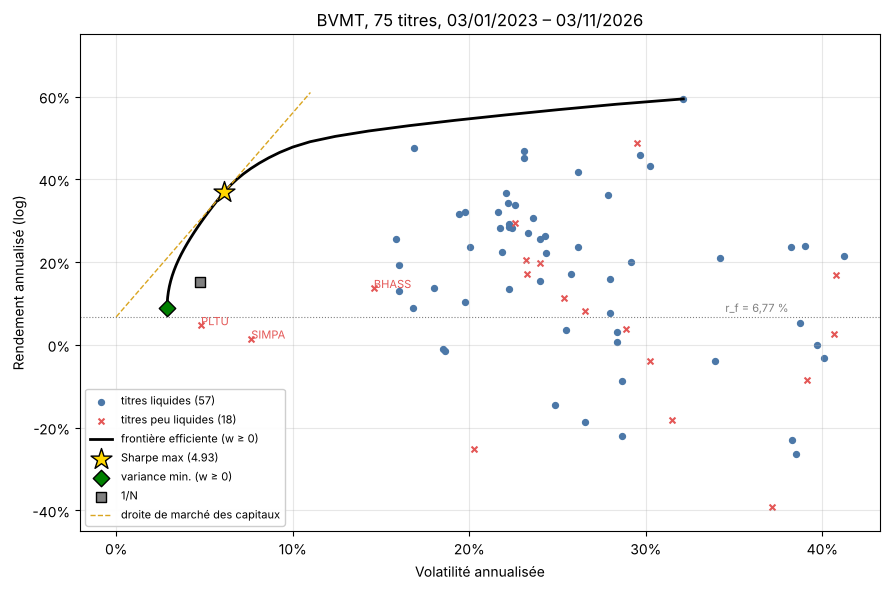

In [14]:
fig, ax = plt.subplots(figsize=(9, 6))
liq = titres.set_index("ticker").retenu.reindex(F.index)
ax.scatter(F.volatilite_annualisee[liq], mu[liq], s=18, c="#4C78A8", label="titres liquides (57)")
ax.scatter(F.volatilite_annualisee[~liq], mu[~liq], s=18, c="#E45756", marker="x", label="titres peu liquides (18)")
ax.plot(front.volatilite, front.rendement, c="black", lw=2, label="frontière efficiente (w ≥ 0)")
r, v, s = perf(w_ms); ax.scatter(v, r, marker="*", s=250, c="gold", ec="k", zorder=5, label=f"Sharpe max ({s:.2f})")
r, v, s = perf(w_gmv_lo); ax.scatter(v, r, marker="D", s=70, c="green", ec="k", zorder=5, label="variance min. (w ≥ 0)")
r, v, s = perf(np.full(len(mu), 1/len(mu))); ax.scatter(v, r, marker="s", s=60, c="gray", ec="k", zorder=5, label="1/N")
x = np.linspace(0, 0.11, 10); ax.plot(x, RF + perf(w_ms)[2] * x, ls="--", c="goldenrod", lw=1, label="droite de marché des capitaux")
ax.axhline(RF, c="gray", lw=0.8, ls=":"); ax.text(0.345, RF + 0.012, "r_f = 6,77 %", color="gray", fontsize=8)
for tk in ["PLTU", "SIMPA", "BHASS"]:
    ax.annotate(tk, (F.loc[tk, "volatilite_annualisee"], mu[tk]), fontsize=8, color="#E45756")
ax.set_xlabel("Volatilité annualisée"); ax.set_ylabel("Rendement annualisé (log)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("BVMT, 75 titres, 03/01/2023 – 03/11/2026"); ax.set_ylim(-0.45, 0.75); ax.legend(fontsize=8, loc="lower left", framealpha=0.95); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(OUT / "frontiere_efficiente.png", dpi=150); plt.show()

### 8. Analyse de sensibilité : 75 titres contre 57 titres liquides

Le guide recommande de refaire Markowitz sur les 57 titres liquides pour mesurer l'effet des titres peu échangés. On réutilise exactement les mêmes fonctions.

In [15]:
liquides = titres[titres.retenu].ticker.tolist()
S57, mu57 = Sigma.loc[liquides, liquides], mu[liquides]
res = []
for univ, S, m in [("75 titres", Sigma, mu), ("57 liquides", S57, mu57)]:
    for nom, w in [("variance min. (forme fermée)", min_var_ferme(S)), ("variance min. (w ≥ 0)", qp(S)),
                   ("Sharpe max. (w ≥ 0)", max_sharpe(S, m, RF)), ("1/N", np.full(len(m), 1/len(m)))]:
        r, v, s = perf(w, m, S)
        top = pd.Series(w, S.index).sort_values(ascending=False)
        res.append({"univers": univ, "portefeuille": nom, "rendement": r, "volatilite": v, "sharpe": s,
                    "nb_titres_>1%": int((w > 0.01).sum()), "1er titre": f"{top.index[0]} ({top.iloc[0]:.0%})",
                    "part titres peu liquides": float(w[[t not in liquides for t in S.index]].sum())})
sens = pd.DataFrame(res); sens.to_csv(OUT / "sensibilite_75_vs_57.csv", index=False)
sens.round(3)

,univers,portefeuille,rendement,volatilite,sharpe,nb_titres_>1%,1er titre,part titres peu liquides
0,75 titres,variance min. (forme fermée),0.089,0.029,0.736,21,PLTU (37%),0.672
1,75 titres,variance min. (w ≥ 0),0.090,0.029,0.765,21,PLTU (37%),0.670
2,75 titres,Sharpe max. (w ≥ 0),0.369,0.061,4.929,23,AB (10%),0.200
3,75 titres,1/N,0.153,0.047,1.798,75,SFBT (1%),0.240
4,57 liquides,variance min. (forme fermée),0.157,0.048,1.881,39,WIFAK (7%),0.000
5,57 liquides,variance min. (w ≥ 0),0.162,0.048,1.963,38,WIFAK (7%),0.000
6,57 liquides,Sharpe max. (w ≥ 0),0.383,0.070,4.521,21,AB (13%),0.000
7,57 liquides,1/N,0.183,0.056,2.077,57,SFBT (2%),0.000


**Lecture.**
- Sur 75 titres, la variance minimale est dominée par des titres peu liquides, et sa volatilité affichée (quelques %) est **illusoire**. Sur 57 titres liquides, elle remonte à un niveau réaliste et se répartit sur des valeurs effectivement négociables (banques, agroalimentaire…).
- Le Sharpe maximal est moins touché, car il cherche du rendement et les titres peu liquides en ont peu.
- **Pour la Phase 3**, cela justifie de présenter les résultats sur les 57 titres liquides comme référence et les 75 titres comme test de sensibilité, ou au moins de commenter ce biais en soutenance.

### 9. Contrôles et récapitulatif des fichiers

In [16]:
ctrl = {
    "rendements : 959 × 75, sans valeur manquante": R.shape == (959, 75) and R.notna().all().all(),
    "dates Tunindex = dates titres": M.index.equals(R.index),
    "features : 75 × 7": F.shape == (75, 7),
    "VaR ≤ 0 et CVaR ≤ VaR (VaR = 0 pour les 3 titres quasi jamais échangés)": bool((F.var_95 <= 0).all() and (F.cvar_95 <= F.var_95 + 1e-12).all()),
    "corrélations : diagonale 1, symétriques": bool(np.allclose(np.diag(P), 1) and np.allclose(P, P.T)),
    "covariance définie positive": bool(np.linalg.eigvalsh(Sigma.values).min() > 0),
    "poids variance min. : somme 1": bool(np.isclose(w_gmv.sum(), 1) and np.isclose(w_gmv_lo.sum(), 1)),
    "poids Sharpe max. : dans [0, 1], somme 1": bool(np.isclose(w_ms.sum(), 1) and (w_ms >= 0).all()),
    "frontière croissante en rendement et volatilité": bool(front.rendement.is_monotonic_increasing),
}
for k, v in ctrl.items(): print("OK " if v else "ÉCHEC ", k)
print(); [print(f"{p.name:40s} {p.stat().st_size/1024:8.1f} Ko") for p in sorted(OUT.iterdir())];

OK  rendements : 959 × 75, sans valeur manquante
OK  dates Tunindex = dates titres
OK  features : 75 × 7
OK  VaR ≤ 0 et CVaR ≤ VaR (VaR = 0 pour les 3 titres quasi jamais échangés)
OK  corrélations : diagonale 1, symétriques
OK  covariance définie positive
OK  poids variance min. : somme 1
OK  poids Sharpe max. : dans [0, 1], somme 1
OK  frontière croissante en rendement et volatilité

correlations_pearson.csv                      1.0 Ko
correlations_spearman.csv                     1.0 Ko
covariance_annualisee.csv                   121.3 Ko
features_titres.csv                          10.7 Ko
frontiere_efficiente.csv                     53.0 Ko
frontiere_efficiente.png                     95.5 Ko
markowitz_sharpe_maximal.csv                  1.6 Ko
markowitz_variance_minimale.csv               3.4 Ko
rendements_log_75.csv                       946.3 Ko
sensibilite_75_vs_57.csv                      1.0 Ko
taux_sans_risque.json                         0.5 Ko
tunindex_rendements.csv     

---

# Partie B — Segmentation et anomalies (7 features)

*Segmentation et détection des anomalies.*


## Segmentation et anomalies sur la BVMT

Projet Math en assurance et finance · 5INFINI · données du 02/01/2023 au 03/11/2026.

**Objectif.** Regrouper les titres qui se ressemblent (k-means) et repérer ceux qui ne ressemblent à aucun autre (Isolation Forest), à partir des 7 features calculées en phase des indicateurs. On travaille dans trois espaces :

| Espace | Variables | Pourquoi |
|---|---|---|
| **RV** | rendement et volatilité standardisés | le plan de l'article de référence, lisible directement |
| **7F** | les 7 features standardisées | toute l'information, mais avec des features redondantes (vol., VaR, CVaR) |
| **ACP** | les composantes principales qui expliquent ≥ 80 % de la variance | mêmes informations, décorrélées et débruitées |

**Entrées** (lecture seule, rien n'est modifié) :
- `fichier des features calculées` : 75 titres × 7 features (sortie de la phase des indicateurs) ;
- `data/processed/qualite_par_titre.csv` : nom, liquidité et statut de chaque titre (sortie de la S2).

**Sorties** : `dossier des résultats de segmentation` (CSV et graphiques), liste en section 11.

**Plan.**
0. Chargement et contrôles
1. Standardisation
2. ACP
3. k-means : choix de k
4. k-means : modèles retenus
5. Isolation Forest
6. Comparaison IF / k-means
7. Interprétation des clusters
8. Nature des anomalies
9. Titres liquides seulement
10. Secteurs
11. Synthèse et fichiers

In [17]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score

GRAINE = 42                       # graine aléatoire fixe (k-means, Isolation Forest)
K_PLAGE = range(3, 9)             # k testés : 3 à 8
TAUX_IF = [0.03, 0.05, 0.08, 0.10]
TAUX_RETENU = 0.05                # justifié en section 5
SEUIL_LIQUIDITE = 0.60            # même seuil qu'en S2

RACINE = Path("..")               # le notebook est dans notebooks/
F_PATH = RACINE / "data" / "s3" / "features_titres.csv"
Q_PATH = RACINE / "data" / "processed" / "qualite_par_titre.csv"
OUT = RACINE / "data" / "processed" / "s4"
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 170, "display.max_columns", 20, "display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

### 0. Chargement et contrôles

On lit les colonnes réellement présentes avant de les utiliser.

- **`features_titres.csv`** : une ligne par titre (`ticker`) et 7 colonnes de features.
- **`qualite_par_titre.csv`** : 85 sociétés, dont les 10 qui ne sont plus cotées.

Les colonnes utilisées dans `qualite_par_titre.csv` :
- `nom` ;
- `part_seances_echangees` : part des séances avec au moins une transaction ;
- `part_rendements_nuls` ;
- `retenu` : True si la société a été échangée au moins 60 % des séances.

In [18]:
F_brut = pd.read_csv(F_PATH)
Q_brut = pd.read_csv(Q_PATH)
print("features_titres.csv :", F_brut.shape, list(F_brut.columns))
print("qualite_par_titre.csv :", Q_brut.shape, list(Q_brut.columns))

F = F_brut.set_index("ticker")
FEATURES = list(F.columns)
Q = Q_brut.dropna(subset=["ticker"]).set_index("ticker").loc[F.index]
info = Q[["nom", "part_seances_echangees", "part_rendements_nuls", "retenu"]].copy()
info["liquide"] = info["retenu"].astype(bool)

assert F.shape == (75, 7) and F.notna().all().all(), "features : 75 × 7 sans manquant attendu"
assert (info.liquide == (info.part_seances_echangees >= SEUIL_LIQUIDITE)).all()
print(f"\n{len(F)} titres, dont {info.liquide.sum()} liquides et {(~info.liquide).sum()} peu liquides (< 60 % de séances échangées)")
F.describe().T[["mean", "std", "min", "50%", "max"]]

features_titres.csv : (75, 8) ['ticker', 'rendement_annualise', 'volatilite_annualisee', 'skewness', 'kurtosis', 'var_95', 'cvar_95', 'beta']
qualite_par_titre.csv : (85, 14) ['ticker', 'nom', 'isin', 'groupe', 'premiere_seance', 'derniere_seance', 'nb_lignes', 'seances_manquantes', 'part_seances_echangees', 'part_rendements_nuls', 'capitaux_median_2023_2025', 'nb_ost', 'retenu', 'motif_exclusion']

75 titres, dont 57 liquides et 18 peu liquides (< 60 % de séances échangées)


,mean,std,min,50%,max
rendement_annualise,0.153,0.201,-0.391,0.172,5.944e-01
volatilite_annualisee,0.260,0.077,0.048,0.243,4.120e-01
skewness,0.471,1.377,-0.777,0.263,1.173e+01
kurtosis,6.043,20.204,-0.947,2.834,1.643e+02
var_95,-0.026,0.012,-0.045,-0.024,0.000e+00
cvar_95,-0.035,0.011,-0.051,-0.038,-4.118e-05
beta,0.432,0.390,-0.190,0.395,1.556e+00


**À noter avant de standardiser.** Les distributions sont très asymétriques : le kurtosis va de −0,9 à 164 (PLTU). Un titre aussi extrême pèsera lourd dans toute méthode fondée sur des distances. C'est voulu ici, puisqu'on cherche justement les titres atypiques, mais il faudra en tenir compte dans l'interprétation.

### 1. Standardisation

Chaque feature est centrée et réduite : z = (x − moyenne) / écart-type, calculés sur les 75 titres.

Sans cette étape, une feature exprimée en grands nombres (le kurtosis, jusqu'à 164) écraserait celles qui varient sur quelques centièmes (VaR, CVaR) dans le calcul des distances de k-means et d'Isolation Forest.

In [19]:
def standardiser(F):
    return pd.DataFrame(StandardScaler().fit_transform(F), index=F.index, columns=F.columns)

Z = standardiser(F)
print("moyennes ≈ 0 :", np.allclose(Z.mean(), 0), "| écarts-types = 1 (ddof=0) :", np.allclose(Z.std(ddof=0), 1))
print("\nTitres avec au moins une feature à |z| > 3 :")
ext = (Z.abs() > 3)
print(pd.DataFrame({"features extrêmes": ext.apply(lambda r: ", ".join(Z.columns[r]), axis=1)})[ext.any(axis=1)].join(info[["part_seances_echangees"]]))

moyennes ≈ 0 : True | écarts-types = 1 (ddof=0) : True

Titres avec au moins une feature à |z| > 3 :
                  features extrêmes  part_seances_echangees
ticker                                                     
SIMPA             kurtosis, cvar_95                   0.118
BHASS                       cvar_95                   0.096
PLTU    skewness, kurtosis, cvar_95                   0.040


### 2. Analyse en composantes principales (ACP)

L'ACP remplace les 7 features corrélées par des composantes non corrélées, classées par part de variance expliquée. On garde le plus petit nombre de composantes qui atteint **80 %** de la variance cumulée.

In [20]:
def acp(Z, seuil=0.80):
    p = PCA(random_state=GRAINE).fit(Z)
    var = pd.DataFrame({"variance_expliquee": p.explained_variance_ratio_,
                        "variance_cumulee": p.explained_variance_ratio_.cumsum()},
                       index=[f"PC{i+1}" for i in range(Z.shape[1])])
    n80 = int(np.argmax(var.variance_cumulee.values >= seuil) + 1)
    charges = pd.DataFrame(p.components_.T, index=Z.columns, columns=var.index)
    scores = pd.DataFrame(p.transform(Z), index=Z.index, columns=var.index)
    return var, n80, charges, scores

var75, N80, charges75, pcs75 = acp(Z)
var75.to_csv(OUT / "acp_variance.csv")
charges75.iloc[:, :3].to_csv(OUT / "acp_charges_3pc.csv")
print(f"Composantes pour atteindre 80 % de variance : {N80}")
print(var75.round(3).T)
print("\nCharges des 3 premières composantes :")
charges75.iloc[:, :3].round(2)

Composantes pour atteindre 80 % de variance : 3
                      PC1    PC2    PC3    PC4    PC5    PC6    PC7
variance_expliquee  0.545  0.239  0.105  0.074  0.021  0.009  0.007
variance_cumulee    0.545  0.784  0.889  0.963  0.984  0.993  1.000

Charges des 3 premières composantes :


,PC1,PC2,PC3
rendement_annualise,0.17,0.49,0.71
volatilite_annualisee,-0.46,-0.08,0.33
skewness,0.38,-0.39,0.42
kurtosis,0.36,-0.49,0.27
var_95,0.47,0.18,-0.26
cvar_95,0.47,0.03,-0.24
beta,0.19,0.57,0.04


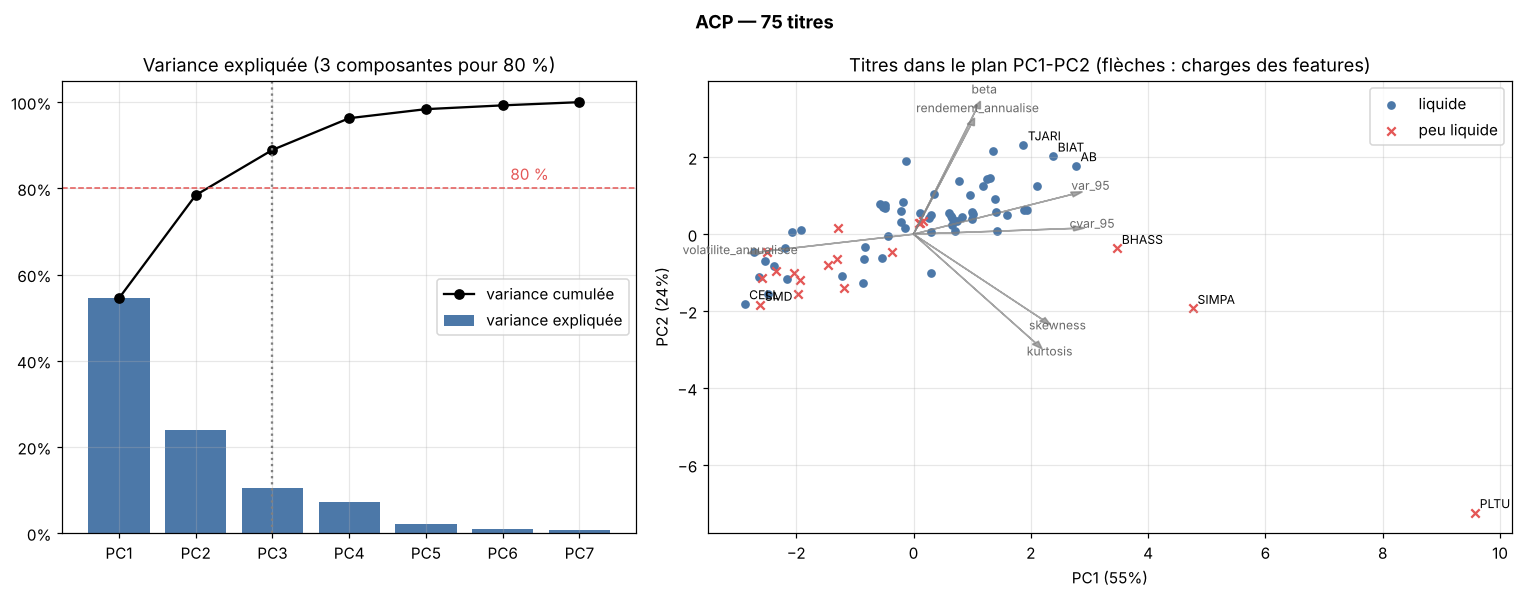

In [21]:
def graph_acp(var, n80, charges, scores, info, titre, fichier):
    fig, ax = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.4]})
    x = np.arange(1, len(var) + 1)
    ax[0].bar(x, var.variance_expliquee, color="#4C78A8", label="variance expliquée")
    ax[0].plot(x, var.variance_cumulee, "o-", c="black", label="variance cumulée")
    ax[0].axhline(0.8, ls="--", c="#E45756", lw=1); ax[0].text(len(var) - 0.4, 0.82, "80 %", color="#E45756", ha="right")
    ax[0].axvline(n80, ls=":", c="gray"); ax[0].set_xticks(x); ax[0].set_xticklabels(var.index)
    ax[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax[0].set_title(f"Variance expliquée ({n80} composantes pour 80 %)"); ax[0].legend(loc="center right")
    liq = info.liquide.reindex(scores.index)
    ax[1].scatter(scores.PC1[liq], scores.PC2[liq], s=22, c="#4C78A8", label="liquide")
    ax[1].scatter(scores.PC1[~liq], scores.PC2[~liq], s=30, c="#E45756", marker="x", label="peu liquide")
    lim = np.abs(scores[["PC1", "PC2"]]).max().max()
    for f, (a, b) in charges[["PC1", "PC2"]].iterrows():
        ax[1].arrow(0, 0, a * lim * 0.6, b * lim * 0.6, color="gray", alpha=0.7, head_width=0.08 * lim / 6)
        ax[1].text(a * lim * 0.67, b * lim * 0.67, f, fontsize=8, color="dimgray", ha="center")
    loin = (scores.PC1 ** 2 + scores.PC2 ** 2).sort_values(ascending=False).index[:8]
    for t in loin:
        ax[1].annotate(t, (scores.PC1[t], scores.PC2[t]), fontsize=8, xytext=(3, 3), textcoords="offset points")
    ax[1].set_xlabel(f"PC1 ({var.variance_expliquee.iloc[0]:.0%})"); ax[1].set_ylabel(f"PC2 ({var.variance_expliquee.iloc[1]:.0%})")
    ax[1].set_title("Titres dans le plan PC1-PC2 (flèches : charges des features)"); ax[1].legend()
    fig.suptitle(titre, fontweight="bold"); fig.tight_layout(); fig.savefig(OUT / fichier, dpi=150); plt.show()

graph_acp(var75, N80, charges75, pcs75, info, "ACP — 75 titres", "s4_acp.png")

**Lecture de l'ACP (75 titres).**
- **3 composantes** suffisent pour dépasser 80 % de la variance. PC1 en explique à elle seule environ 55 %.
- **PC1 est un axe « risque »** : la VaR et la CVaR (négatives, donc plus grandes quand le risque est faible) pèsent dans un sens, la volatilité dans l'autre. Les titres à droite sont peu risqués, ou plutôt *paraissent* peu risqués : skewness et kurtosis chargent aussi positivement, et c'est la signature des titres dont le prix bouge rarement mais par sauts.
- **PC2 est un axe « marché et rendement »** : il oppose le bêta et le rendement d'un côté au kurtosis et à la skewness de l'autre.
- **PC3 est surtout porté par le rendement.**
- Les titres peu liquides (croix rouges) s'étalent loin de la masse : PLTU, SIMPA et BHASS sont tirés par le kurtosis et la VaR nulle.

### 3. k-means : choix de k

On applique k-means (initialisation **k-means++**, 50 initialisations, graine 42) dans les trois espaces, pour k = 3 à 8. Quatre critères sont calculés pour chaque k :

| Critère | Ce qu'il mesure | Meilleur k |
|---|---|---|
| Coude | inertie intra-cluster ; on cherche le point où ajouter un cluster ne fait plus beaucoup baisser l'inertie | point de courbure maximale (méthode de la corde) |
| Silhouette | ressemblance d'un titre à son cluster comparée au cluster voisin, entre −1 et 1 | le plus élevé |
| Calinski-Harabasz (CH) | dispersion entre clusters / dispersion dans les clusters | le plus élevé |
| Davies-Bouldin (DB) | ressemblance moyenne de chaque cluster à son plus proche voisin | le plus bas |

**Règle de choix, appliquée identiquement partout.** Chaque critère vote pour un k ; on retient le k qui recueille le plus de votes, donc soutenu par **au moins deux critères**. En cas d'égalité, la silhouette tranche. On **signale** :
- tout k retenu au bord de la plage (3 ou 8) : le vrai optimum pourrait être en dehors ;
- tout cluster d'un seul titre ;
- toute silhouette < 0,5, qui indique une structure de groupes faible.

In [22]:
def coude(ks, inerties):
    """k de courbure maximale : point le plus éloigné, sous la corde, de la courbe d'inertie normalisée."""
    x = (np.array(ks) - ks[0]) / (ks[-1] - ks[0])
    y = (np.array(inerties) - min(inerties)) / (max(inerties) - min(inerties))
    return ks[int(np.argmax((1 - x) - y))]

def espaces(Z, n80):
    p = PCA(n_components=n80, random_state=GRAINE).fit(Z)
    return {"RV": pd.DataFrame(Z[["rendement_annualise", "volatilite_annualisee"]].values, index=Z.index, columns=["z_rendement", "z_volatilite"]),
            "7F": Z.copy(),
            "ACP": pd.DataFrame(p.transform(Z), index=Z.index, columns=[f"PC{i+1}" for i in range(n80)])}

def kmeans(X, k):
    return KMeans(n_clusters=k, init="k-means++", n_init=50, random_state=GRAINE).fit(X)

def choix_k(X):
    lignes = []
    for k in K_PLAGE:
        km = kmeans(X, k); tailles = np.bincount(km.labels_)
        lignes.append({"k": k, "inertie": km.inertia_, "silhouette": silhouette_score(X, km.labels_),
                       "calinski_harabasz": calinski_harabasz_score(X, km.labels_),
                       "davies_bouldin": davies_bouldin_score(X, km.labels_),
                       "tailles": " / ".join(map(str, sorted(tailles, reverse=True))), "nb_singletons": int((tailles == 1).sum())})
    t = pd.DataFrame(lignes).set_index("k")
    ks = list(t.index)
    votes = {"coude": coude(ks, t.inertie.tolist()), "silhouette": int(t.silhouette.idxmax()),
             "calinski_harabasz": int(t.calinski_harabasz.idxmax()), "davies_bouldin": int(t.davies_bouldin.idxmin())}
    compte = pd.Series(list(votes.values())).value_counts()
    meilleurs = compte[compte == compte.max()].index.tolist()
    k_ret = int(max(meilleurs, key=lambda k: t.silhouette[k]))
    return t, votes, k_ret

def rapport_k(nom, t, votes, k):
    soutiens = [c for c, v in votes.items() if v == k]
    alertes = []
    if k in (min(K_PLAGE), max(K_PLAGE)): alertes.append(f"k = {k} AU BORD de la plage {min(K_PLAGE)}-{max(K_PLAGE)}")
    if t.nb_singletons[k] > 0: alertes.append(f"{t.nb_singletons[k]} cluster(s) d'un seul titre")
    if t.silhouette[k] < 0.5: alertes.append(f"silhouette {t.silhouette[k]:.2f} < 0,5 : structure faible")
    print(f"{nom:4s} votes {votes} → k retenu = {k} (soutenu par : {', '.join(soutiens)})")
    for a in alertes: print("      ⚠", a)
    return {"espace": nom, "k_retenu": k, "criteres_en_faveur": ", ".join(soutiens), **{f"vote_{c}": v for c, v in votes.items()},
            "silhouette": round(t.silhouette[k], 3), "tailles": t.tailles[k], "alertes": " ; ".join(alertes)}

ESP75 = espaces(Z, N80)
CHOIX75, TABK75, K75 = [], {}, {}
for nom, X in ESP75.items():
    t, votes, k = choix_k(X); TABK75[nom] = t; K75[nom] = k
    CHOIX75.append(rapport_k(nom, t, votes, k))
pd.concat({n: t for n, t in TABK75.items()}, names=["espace"]).to_csv(OUT / "choix_k_criteres.csv")
pd.DataFrame(CHOIX75).to_csv(OUT / "choix_k_retenus.csv", index=False)
pd.concat({n: t[["silhouette", "calinski_harabasz", "davies_bouldin", "tailles"]] for n, t in TABK75.items()}, axis=1).round(3)

RV   votes {'coude': 5, 'silhouette': 8, 'calinski_harabasz': 8, 'davies_bouldin': 8} → k retenu = 8 (soutenu par : silhouette, calinski_harabasz, davies_bouldin)
      ⚠ k = 8 AU BORD de la plage 3-8
      ⚠ silhouette 0.44 < 0,5 : structure faible
7F   votes {'coude': 5, 'silhouette': 3, 'calinski_harabasz': 3, 'davies_bouldin': 3} → k retenu = 3 (soutenu par : silhouette, calinski_harabasz, davies_bouldin)
      ⚠ k = 3 AU BORD de la plage 3-8
      ⚠ 1 cluster(s) d'un seul titre
      ⚠ silhouette 0.41 < 0,5 : structure faible


ACP  votes {'coude': 5, 'silhouette': 3, 'calinski_harabasz': 8, 'davies_bouldin': 3} → k retenu = 3 (soutenu par : silhouette, davies_bouldin)
      ⚠ k = 3 AU BORD de la plage 3-8
      ⚠ 1 cluster(s) d'un seul titre
      ⚠ silhouette 0.47 < 0,5 : structure faible


RV                                                                            7F                                                                      \
  silhouette calinski_harabasz davies_bouldin                           tailles silhouette calinski_harabasz davies_bouldin                            tailles   
k                                                                                                                                                                
3      0.407            57.181          0.820                      37 / 26 / 12      0.406            56.978          0.657                        48 / 26 / 1   
4      0.421            59.844          0.839                 37 / 17 / 11 / 10      0.314            54.899          0.904                   33 / 25 / 16 / 1   
5      0.383            62.765          0.802            26 / 17 / 11 / 11 / 10      0.309            54.459          0.829               30 / 25 / 17 / 2 / 1   
6      0.401            65.790          0.734        22 / 13 / 11 / 11 / 10 / 8      0.288            53.892          0.912          29 / 16 / 16 / 11 / 2 / 1   
7      0.413            69.530          0.667     21 / 15 / 11 / 10 / 8 / 7 / 3      0.274            51.563          0.922      25 / 16 / 15 / 10 / 6 / 2 / 1   
8      0.441            72.581          0.626  22 / 13 / 11 / 9 / 8 / 7 / 3 / 2      0.283            51.417          0.902  21 / 16 / 12 / 10 / 7 / 6 / 2 / 1   

         ACP                                                                     
  silhouette calinski_harabasz davies_bouldin                           tailles  
k                                                                                
3      0.469            77.406          0.550                       47 / 27 / 1  
4      0.412            78.114          0.730                  38 / 26 / 10 / 1  
5      0.370            78.373          0.702              32 / 23 / 17 / 2 / 1  
6      0.367            85.191          0.750          28 / 18 / 17 / 9 / 2 / 1  
7      0.373            88.261          0.708      27 / 17 / 14 / 8 / 6 / 2 / 1  
8      0.382            92.859          0.694  23 / 16 / 14 / 8 / 6 / 5 / 2 / 1

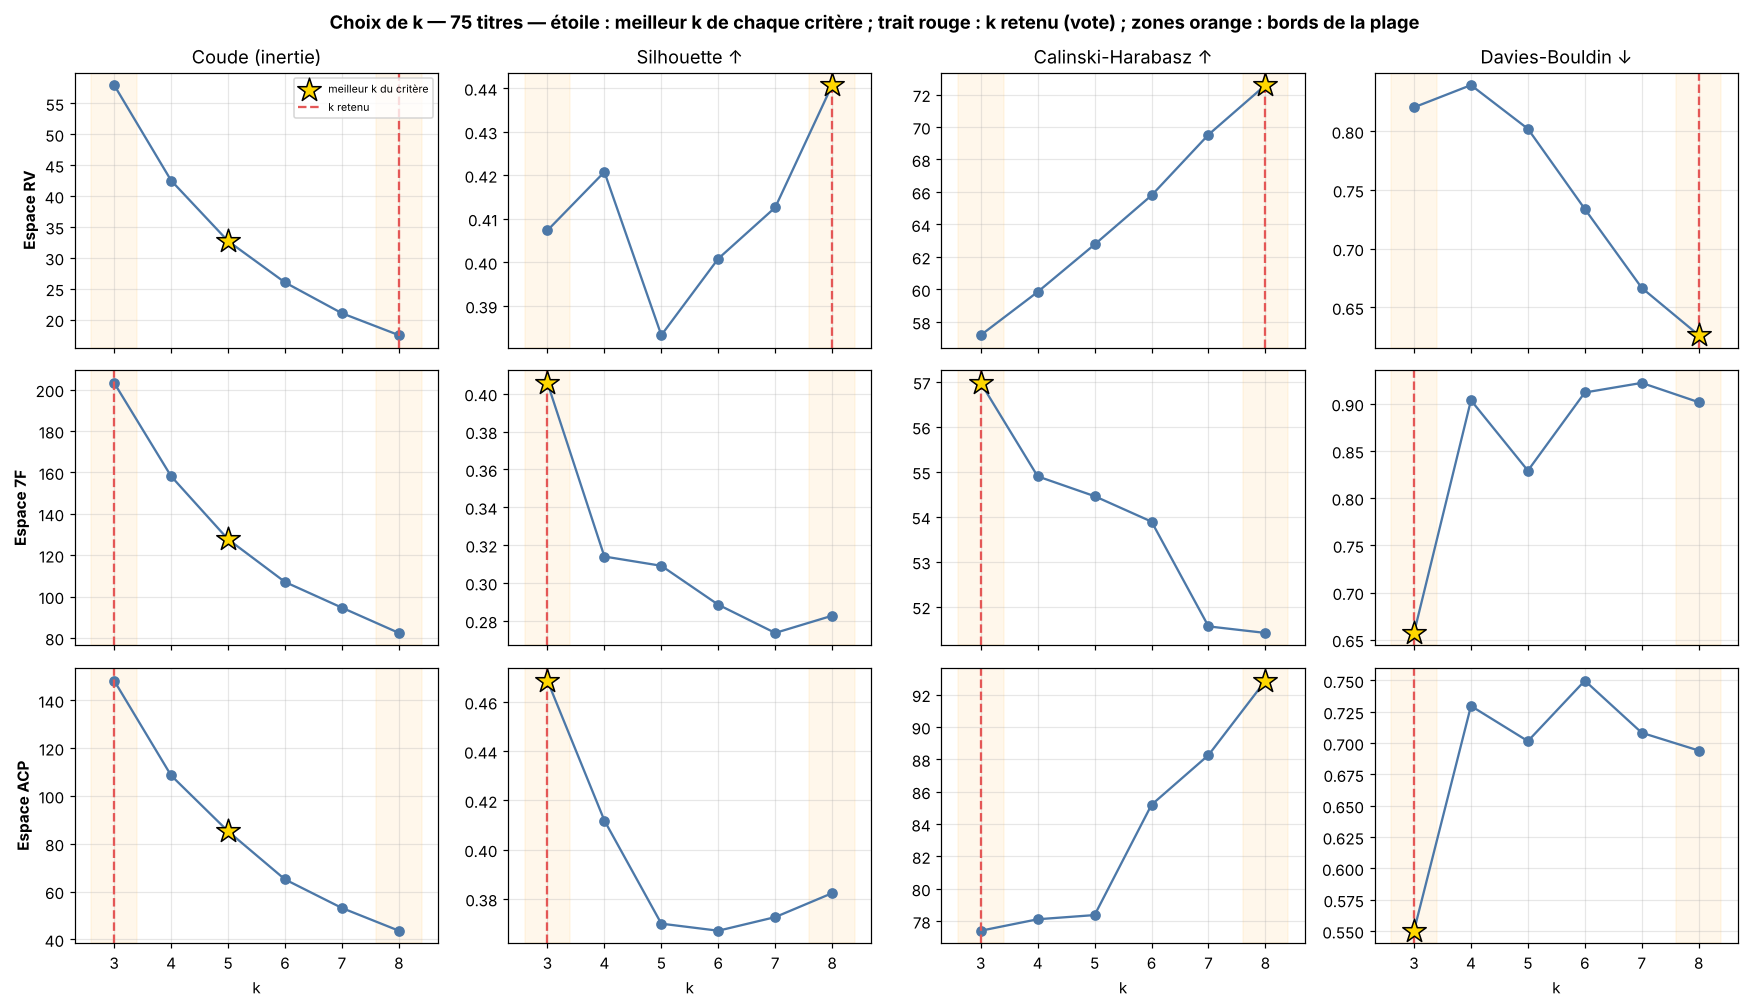

In [23]:
def graph_k(tabs, kret, titre, fichier):
    crit = [("inertie", "Coude (inertie)", None), ("silhouette", "Silhouette ↑", "max"),
            ("calinski_harabasz", "Calinski-Harabasz ↑", "max"), ("davies_bouldin", "Davies-Bouldin ↓", "min")]
    fig, ax = plt.subplots(len(tabs), 4, figsize=(16, 3.1 * len(tabs)), sharex=True)
    for i, (nom, t) in enumerate(tabs.items()):
        for j, (c, lab, sens) in enumerate(crit):
            a = ax[i, j]; a.plot(t.index, t[c], "o-", c="#4C78A8")
            vote = coude(list(t.index), t.inertie.tolist()) if sens is None else (t[c].idxmax() if sens == "max" else t[c].idxmin())
            a.scatter([vote], [t.loc[vote, c]], marker="*", s=260, c="gold", ec="k", zorder=6, label="meilleur k du critère")
            a.axvline(kret[nom], c="#E45756", ls="--", lw=1.5, label="k retenu")
            if i == 0 and j == 0: a.legend(fontsize=7, loc="upper right")
            a.axvspan(2.6, 3.4, color="orange", alpha=0.08); a.axvspan(7.6, 8.4, color="orange", alpha=0.08)
            if i == 0: a.set_title(lab)
            if j == 0: a.set_ylabel(f"Espace {nom}", fontweight="bold")
            if i == len(tabs) - 1: a.set_xlabel("k")
    fig.suptitle(titre + " — étoile : meilleur k de chaque critère ; trait rouge : k retenu (vote) ; zones orange : bords de la plage", fontweight="bold")
    fig.tight_layout(); fig.savefig(OUT / fichier, dpi=150); plt.show()

graph_k(TABK75, K75, "Choix de k — 75 titres", "s4_choix_k.png")

**Lecture du choix de k (75 titres).**
- **Espace RV** : silhouette, CH et DB s'améliorent tous jusqu'à k = 8, et k = 8 est donc retenu, **au bord de la plage**. Ces critères continuent de progresser parce que le plan rendement-volatilité forme un nuage continu, sans groupes naturels : plus on découpe, plus les morceaux sont compacts. Le coude (k = 5) est le seul critère qui suggère un nombre plus modeste.
- **Espaces 7F et ACP** : k = 3 est retenu, **au bord de la plage**, et l'un des 3 clusters est **un singleton : PLTU**. Ce singleton est là quel que soit k (voir la colonne `nb_singletons` de `choix_k_criteres.csv`). Ce n'est donc pas un groupe financier, mais un titre si extrême qu'il forme son propre cluster. Avec k = 3, le partage réel n'oppose que deux groupes.
- **Les silhouettes restent faibles partout** (0,41 à 0,47 au k retenu) : les « groupes » de la BVMT sont peu séparés. C'est une limite à affirmer clairement, car l'article ne la mesure pas.

### 4. k-means : modèles retenus

In [24]:
def ajuster(espaces, kret):
    lab = {}
    for nom, X in espaces.items():
        km = kmeans(X, kret[nom])
        # numérotation stable : cluster 1 = le plus grand, etc.
        ordre = pd.Series(km.labels_).value_counts().index
        lab[nom] = pd.Series(pd.Series(km.labels_).map({c: i + 1 for i, c in enumerate(ordre)}).values, index=X.index)
    return pd.DataFrame(lab).add_prefix("cluster_")

CL75 = ajuster(ESP75, K75)
for c in CL75:
    tailles = CL75[c].value_counts().sort_index()
    print(f"{c:12s} tailles : {dict(tailles)}  | singletons : {[CL75.index[CL75[c] == k][0] for k in tailles.index[tailles == 1]]}")

cluster_RV   tailles : {1: np.int64(22), 2: np.int64(13), 3: np.int64(11), 4: np.int64(9), 5: np.int64(8), 6: np.int64(7), 7: np.int64(3), 8: np.int64(2)}  | singletons : []
cluster_7F   tailles : {1: np.int64(48), 2: np.int64(26), 3: np.int64(1)}  | singletons : ['PLTU']
cluster_ACP  tailles : {1: np.int64(47), 2: np.int64(27), 3: np.int64(1)}  | singletons : ['PLTU']


### 5. Isolation Forest

Isolation Forest construit des arbres de découpes aléatoires : un titre **anormal s'isole en peu de découpes**. On utilise 500 arbres et la graine 42, dans les trois mêmes espaces.

Le **score d'anomalie** (ici −`score_samples`, plus haut = plus anormal) ne dépend pas du taux de contamination. Le taux ne fait que fixer **le seuil** au-delà duquel un titre est signalé. On peut donc comparer les taux 3, 5, 8 et 10 % sur les mêmes scores.

**Choix du taux : 5 %**, soit 4 titres sur 75, pour trois raisons :
1. C'est le taux de l'article de référence, ce qui rend les résultats comparables.
2. Le tableau de stabilité ci-dessous montre qu'à 5 %, les titres signalés font presque tous partie du noyau signalé à tous les taux. À 8-10 %, des titres liquides au profil seulement un peu atypique apparaissent et varient d'un espace à l'autre.
3. Le graphique des scores triés montre une rupture après les 3 à 5 premiers titres dans chaque espace.

On appelle **anomalie stable** un titre signalé dans au moins 8 des 12 combinaisons (3 espaces × 4 taux).

In [25]:
def isolation(espaces):
    scores, sig = {}, {}
    for nom, X in espaces.items():
        f = IsolationForest(n_estimators=500, contamination="auto", random_state=GRAINE).fit(X)
        s = pd.Series(-f.score_samples(X), index=X.index)       # plus haut = plus anormal
        scores[nom] = s
        for taux in TAUX_IF:
            n = int(np.ceil(taux * len(s)))                      # nombre de titres signalés à ce taux
            sig[(nom, taux)] = s.index.isin(s.nlargest(n).index)
    S = pd.DataFrame(scores).add_prefix("score_if_")
    SIG = pd.DataFrame(sig, index=S.index)
    return S, SIG

SC75, SIG75 = isolation(ESP75)
# contrôle : notre seuil par rang donne les mêmes titres que IsolationForest(contamination=taux)
for nom, X in ESP75.items():
    for taux in TAUX_IF:
        f = IsolationForest(n_estimators=500, contamination=taux, random_state=GRAINE).fit(X)
        assert set(X.index[f.predict(X) == -1]) == set(SIG75.index[SIG75[(nom, taux)]]), (nom, taux)
print("Contrôle OK : identique à IsolationForest(contamination=taux) pour les 12 combinaisons")

def tableau_stabilite(SIG):
    lignes = []
    for (nom, taux), col in SIG.items():
        lignes.append({"espace": nom, "taux": f"{taux:.0%}", "nb_signales": int(col.sum()),
                       "titres_signales": ", ".join(sorted(SIG.index[col]))})
    return pd.DataFrame(lignes)

STAB75 = tableau_stabilite(SIG75)
NB75 = SIG75.sum(axis=1).rename("nb_signalements_sur_12")
STAB75.to_csv(OUT / "stabilite_isolation_forest.csv", index=False)
print(STAB75.to_string(index=False))
print("\nNombre de signalements par titre (sur 12), titres signalés au moins une fois :")
print(NB75[NB75 > 0].sort_values(ascending=False).to_frame().join(info[["part_seances_echangees", "liquide"]]).to_string())

Contrôle OK : identique à IsolationForest(contamination=taux) pour les 12 combinaisons
espace taux  nb_signales                                  titres_signales
    RV   3%            3                                 PLTU, SMD, SOTET
    RV   5%            4                          PLTU, SIMPA, SMD, SOTET
    RV   8%            6               AB, ALKIM, PLTU, SIMPA, SMD, SOTET
    RV  10%            8     AB, ALKIM, BHL, PLTU, SCB, SIMPA, SMD, SOTET
    7F   3%            3                               BHASS, PLTU, SIMPA
    7F   5%            4                           AB, BHASS, PLTU, SIMPA
    7F   8%            6             AB, ALKIM, BHASS, PLTU, SIMPA, SOTET
    7F  10%            8 AB, ALKIM, BHASS, BIAT, PLTU, SIMPA, SOTET, TAIR
   ACP   3%            3                               PLTU, SIMPA, SOTET
   ACP   5%            4                        BHASS, PLTU, SIMPA, SOTET
   ACP   8%            6           ALKIM, BHASS, CELL, PLTU, SIMPA, SOTET
   ACP  10%            8 

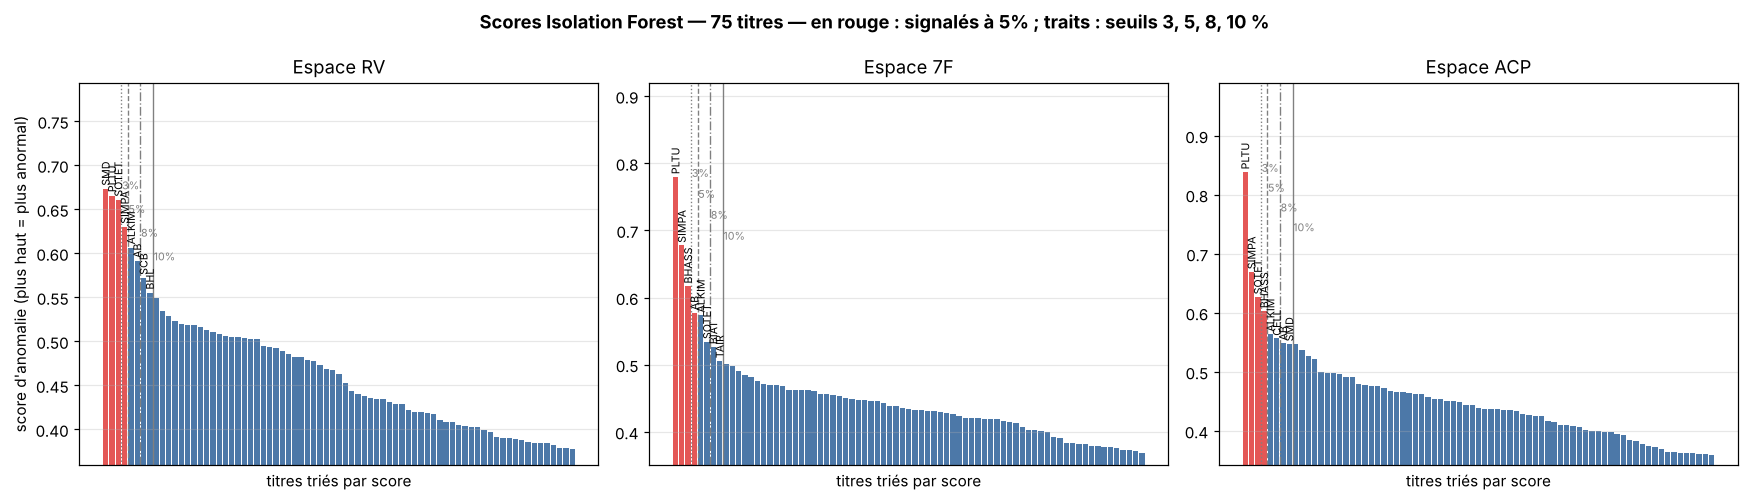

In [26]:
def graph_scores(SC, SIG, titre, fichier, n_lab=8):
    fig, ax = plt.subplots(1, len(SC.columns), figsize=(16, 4.6))
    for a, c in zip(ax, SC.columns):
        nom = c.replace("score_if_", ""); s = SC[c].sort_values(ascending=False)
        n5 = int(np.ceil(TAUX_RETENU * len(s)))
        couleurs = ["#E45756" if i < n5 else "#4C78A8" for i in range(len(s))]
        a.bar(range(len(s)), s.values, color=couleurs, width=0.85)
        for taux, ls in zip(TAUX_IF, [":", "--", "-.", "-"]):
            n = int(np.ceil(taux * len(s))); a.axvline(n - 0.5, ls=ls, c="gray", lw=0.9)
            a.text(n - 0.4, s.max() * (1.0 - 0.04 * TAUX_IF.index(taux)), f"{taux:.0%}", fontsize=7, color="gray")
        for i, t in enumerate(s.index[:n_lab]):
            a.text(i, s.iloc[i] + 0.004, t, rotation=90, fontsize=7, ha="center", va="bottom")
        a.set_ylim(s.min() * 0.95, s.max() * 1.18); a.set_title(f"Espace {nom}"); a.set_xlabel("titres triés par score")
        a.set_xticks([])
    ax[0].set_ylabel("score d'anomalie (plus haut = plus anormal)")
    fig.suptitle(titre + f" — en rouge : signalés à {TAUX_RETENU:.0%} ; traits : seuils 3, 5, 8, 10 %", fontweight="bold")
    fig.tight_layout(); fig.savefig(OUT / fichier, dpi=150); plt.show()

graph_scores(SC75, SIG75, "Scores Isolation Forest — 75 titres", "s4_scores_isolation_forest.png")

**Lecture.**
- **PLTU et SIMPA** sont signalés dans toutes les combinaisons ou presque : ce sont les anomalies les plus stables.
- **SOTET et BHASS** viennent ensuite. AB (Amen Bank) apparaît dans une partie des combinaisons.
- **Trois anomalies stables** (au moins 8 signalements sur 12) : PLTU (12), SIMPA (11) et SOTET (10).
- Au-delà de 5 %, les titres ajoutés changent d'un espace à l'autre (ALKIM, CELL, BIAT, TAIR, BHL, SCB…). C'est le signe que le seuil devient arbitraire, et c'est pour cela qu'on retient 5 %.

### 6. Comparaison : anomalies Isolation Forest et titres isolés par k-means

**Définitions.**
- **Isolé par k-means** : titre appartenant à un cluster d'**au plus 2 titres** dans au moins un espace, au k retenu.
- **Signalé par IF** : titre signalé au taux retenu (5 %) dans au moins un espace.

On compare aussi avec les anomalies stables (au moins 8 signalements sur 12).

In [27]:
def comparaison(CL, SIG, NB):
    iso = set()
    for c in CL:
        t = CL[c].value_counts(); iso |= set(CL.index[CL[c].isin(t[t <= 2].index)])
    if_ = set(SIG.index[SIG.xs(TAUX_RETENU, level=1, axis=1).any(axis=1)])
    stables = set(NB.index[NB >= 8])
    lignes = [("en commun (IF et k-means)", sorted(if_ & iso)), ("seulement Isolation Forest", sorted(if_ - iso)),
              ("seulement k-means", sorted(iso - if_))]
    tab = pd.DataFrame([{"categorie": c, "nb": len(l), "titres": ", ".join(l)} for c, l in lignes])
    return tab, iso, if_, stables

COMP75, ISO75, IF75, STABLES75 = comparaison(CL75, SIG75, NB75)
COMP75.to_csv(OUT / "comparaison_if_kmeans.csv", index=False)
print(COMP75.to_string(index=False))
print("\nAnomalies stables (≥ 8/12) :", sorted(STABLES75))

                 categorie  nb                titres
 en commun (IF et k-means)   2           PLTU, SIMPA
seulement Isolation Forest   4 AB, BHASS, SMD, SOTET
         seulement k-means   0                      

Anomalies stables (≥ 8/12) : ['PLTU', 'SIMPA', 'SOTET']


**Lecture.** Les deux méthodes s'accordent sur le cœur : les titres qui forment un cluster minuscule dans k-means sont aussi ceux qu'Isolation Forest isole le plus vite. C'est attendu, puisque k-means et IF réagissent tous les deux aux points éloignés de la masse. Les titres signalés par une seule méthode sont des cas intermédiaires : IF les isole sans qu'ils soient assez loin pour former leur propre cluster, ou l'inverse.

### 7. Interprétation des clusters

Pour chaque cluster de chaque espace, on calcule :
- la taille et la liste des titres ;
- les **médianes** du rendement, de la volatilité, du bêta et de la liquidité (part de séances échangées). La médiane est préférée à la moyenne parce qu'un seul titre extrême fausse une moyenne ;
- le nombre de titres peu liquides et le nombre d'anomalies IF (taux 5 %, même espace).

**Nom financier court.** Il est attribué par une règle fixe, appliquée à tous les clusters, et non choisi à la main :
- Si la liquidité médiane du cluster est inférieure à 60 %, on le nomme « Peu liquides, prix figés ».
- Sinon, on compare son rendement et sa volatilité médians à ceux de l'univers :

| | Volatilité basse | Volatilité haute |
|---|---|---|
| **Rendement haut** | « Croissance régulière » | « Forte hausse, volatiles » |
| **Rendement bas** | « Défensives, rendement faible » | « Volatiles, rendement faible » |

- Un rendement médian négatif ajoute « (en baisse) ». Un bêta médian ≥ 1,2 ajoute « , sensibles au marché » ; un bêta ≤ 0,3 ajoute « , peu liés au marché ».

Aucun secteur n'est utilisé (voir section 10).

In [28]:
def nommer(r, ref):
    if r.liquidite_mediane < SEUIL_LIQUIDITE:
        nom = "Peu liquides, prix figés"
    else:
        haut_r = r.rendement_median >= ref["rendement"]; haut_v = r.volatilite_mediane >= ref["volatilite"]
        nom = {(True, False): "Croissance régulière", (True, True): "Forte hausse, volatiles",
               (False, False): "Défensives, rendement faible", (False, True): "Volatiles, rendement faible"}[(haut_r, haut_v)]
        if r.rendement_median < 0: nom += " (en baisse)"
    if r.beta_median >= 1.2: nom += ", sensibles au marché"
    elif r.beta_median <= 0.3: nom += ", peu liés au marché"
    if r.taille == 1: nom = f"Singleton {r.titres} : " + nom.lower()
    return nom

def interpreter(CL, F, info, SIG):
    ref = {"rendement": F.rendement_annualise.median(), "volatilite": F.volatilite_annualisee.median()}
    lignes = []
    for c in CL:
        nom_esp = c.replace("cluster_", "")
        sig = SIG[(nom_esp, TAUX_RETENU)]
        for k, idx in CL.groupby(c).groups.items():
            idx = list(idx)
            lignes.append({"espace": nom_esp, "cluster": int(k), "taille": len(idx), "titres": ", ".join(sorted(idx)),
                           "rendement_median": F.loc[idx, "rendement_annualise"].median(),
                           "volatilite_mediane": F.loc[idx, "volatilite_annualisee"].median(),
                           "beta_median": F.loc[idx, "beta"].median(),
                           "liquidite_mediane": info.loc[idx, "part_seances_echangees"].median(),
                           "nb_peu_liquides": int((~info.loc[idx, "liquide"]).sum()),
                           "nb_anomalies_if": int(sig.loc[idx].sum())})
    T = pd.DataFrame(lignes)
    T["nom_financier"] = T.apply(lambda r: nommer(r, ref), axis=1)
    return T

INT75 = interpreter(CL75, F, info, SIG75)
INT75.to_csv(OUT / "interpretation_clusters.csv", index=False)
fmt = INT75.copy()
for c in ["rendement_median", "volatilite_mediane", "liquidite_mediane"]: fmt[c] = fmt[c].map("{:.0%}".format)
fmt["beta_median"] = fmt.beta_median.map("{:.2f}".format)
print(fmt.drop(columns="titres").to_string(index=False))

espace  cluster  taille rendement_median volatilite_mediane beta_median liquidite_mediane  nb_peu_liquides  nb_anomalies_if                                                 nom_financier
    RV        1      22              28%                22%        0.50               96%                3                0                                          Croissance régulière
    RV        2      13              11%                27%        0.40               90%                4                0                                   Volatiles, rendement faible
    RV        3      11               5%                39%        0.14               71%                3                0               Volatiles, rendement faible, peu liés au marché
    RV        4       9              13%                17%        0.63              100%                1                0                                  Défensives, rendement faible
    RV        5       8              45%                29%        0.4

In [29]:
for _, r in INT75.iterrows():
    print(f"[{r.espace} · cluster {r.cluster} · {r.taille} titres] {r.nom_financier}\n    {r.titres}")

[RV · cluster 1 · 22 titres] Croissance régulière
    AB, AL, AMV, ARTES, ASSMA, BNA, CITY, DH, HL, LNDOR, PGH, SAM, SMART, SOTUV, SPDIT, STAR, STPIL, TJARI, TJL, TPR, TRE, UBCI
[RV · cluster 2 · 13 titres] Volatiles, rendement faible
    AST, ATB, BH, BL, BNASS, ICF, MAG, NAKL, SIAME, SITS, STB, TLNET, UIB
[RV · cluster 3 · 11 titres] Volatiles, rendement faible, peu liés au marché
    ASSAD, BHL, BTE, MNP, PLAST, SOKNA, SOMOC, SOTEM, STIP, TGH, UADH
[RV · cluster 4 · 9 titres] Défensives, rendement faible
    BHASS, BIAT, BT, CC, OTH, SAH, SFBT, UMED, WIFAK
[RV · cluster 5 · 8 titres] Forte hausse, volatiles
    ATL, CIL, MGR, MPBS, SOTET, STA, TINV, TLS
[RV · cluster 6 · 7 titres] Volatiles, rendement faible (en baisse), peu liés au marché
    AETEC, ALKIM, ECYCL, NBL, SIPHA, STPAP, TAIR
[RV · cluster 7 · 3 titres] Volatiles, rendement faible (en baisse), peu liés au marché
    CELL, SCB, SMD
[RV · cluster 8 · 2 titres] Peu liquides, prix figés, peu liés au marché
    PLTU, SIMPA
[7

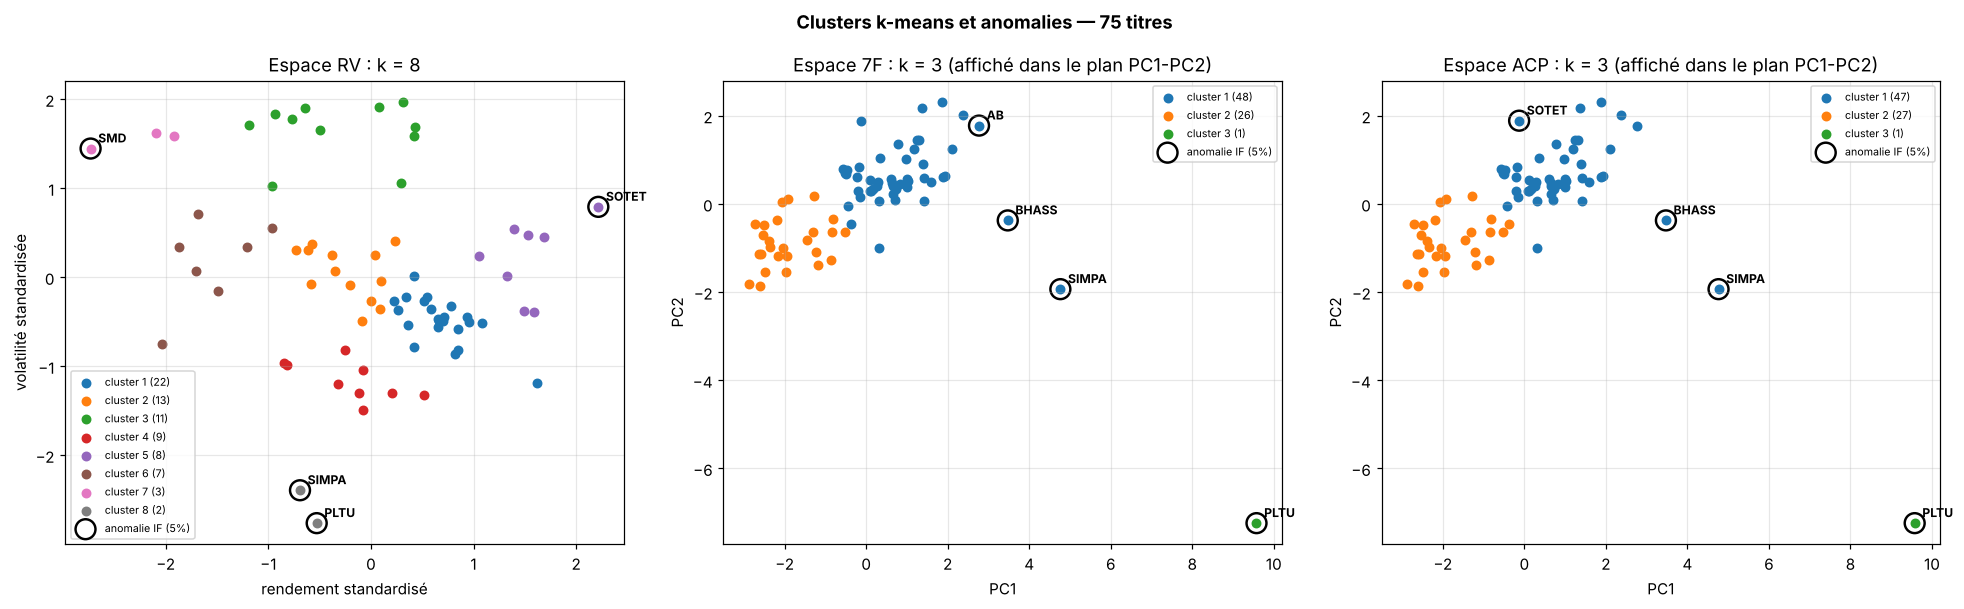

In [30]:
def graph_clusters(ESP, CL, SIG, pcs, titre, fichier):
    fig, ax = plt.subplots(1, 3, figsize=(18, 5.6))
    vues = [("RV", ESP["RV"].iloc[:, 0], ESP["RV"].iloc[:, 1], "rendement standardisé", "volatilité standardisée"),
            ("7F", pcs.PC1, pcs.PC2, "PC1", "PC2"), ("ACP", pcs.PC1, pcs.PC2, "PC1", "PC2")]
    cmap = plt.get_cmap("tab10")
    for a, (nom, x, y, xl, yl) in zip(ax, vues):
        lab = CL[f"cluster_{nom}"]
        for k in sorted(lab.unique()):
            m = lab == k; a.scatter(x[m], y[m], s=30, color=cmap(k - 1), label=f"cluster {k} ({m.sum()})")
        s = SIG[(nom, TAUX_RETENU)]
        a.scatter(x[s], y[s], s=170, facecolors="none", edgecolors="black", lw=1.6, label=f"anomalie IF ({TAUX_RETENU:.0%})")
        for t in lab.index[s]:
            a.annotate(t, (x[t], y[t]), fontsize=8, xytext=(5, 4), textcoords="offset points", fontweight="bold")
        a.set_xlabel(xl); a.set_ylabel(yl)
        a.set_title(f"Espace {nom} : k = {lab.nunique()}" + (" (affiché dans le plan PC1-PC2)" if nom != "RV" else ""))
        a.legend(fontsize=7, loc="best")
    fig.suptitle(titre, fontweight="bold"); fig.tight_layout(); fig.savefig(OUT / fichier, dpi=150); plt.show()

graph_clusters(ESP75, CL75, SIG75, pcs75, "Clusters k-means et anomalies — 75 titres", "s4_clusters.png")

**Lecture des clusters (75 titres).**
- **Dans les espaces 7F et ACP**, la partition est grossière : un singleton, PLTU, et deux grands groupes qui opposent les titres les plus risqués aux autres. On ne peut pas en tirer de vraie diversification : choisir « un titre par cluster » reviendrait à imposer PLTU dans le portefeuille.
- **Dans l'espace RV**, les 8 clusters découpent le nuage rendement-volatilité en tranches. C'est la logique du « triangle » de l'article : titres réguliers, spéculatifs et en baisse. Les deux titres aux prix les plus figés (PLTU, SIMPA) forment le plus petit cluster ; les autres titres peu liquides se répartissent surtout dans les tranches volatiles à rendement faible ou négatif.
- Les noms sont descriptifs et viennent d'une règle fixe : ils résument les chiffres, ils ne disent rien du secteur ni de la santé financière des sociétés.

### 8. Nature de chaque anomalie : artefact d'illiquidité ou performance extrême ?

Règle appliquée à chaque titre signalé au moins une fois par Isolation Forest :

- **Artefact d'illiquidité** : le titre est échangé moins de 60 % des séances ou a plus de 50 % de rendements nuls. Son profil atypique (volatilité basse, kurtosis énorme, VaR nulle) vient de prix qui ne bougent pas, pas d'un comportement économique.
- **Performance extrême** : le titre est liquide, et au moins une feature dépasse |z| > 2. On précise laquelle, et le sens pour le rendement.
- **Atypique modéré** : le titre est liquide et aucune feature ne dépasse |z| > 2. Il est isolé par une combinaison de features plutôt que par une valeur extrême.

Conformément à la consigne, **aucune anomalie n'est présentée comme une société en difficulté** : ce jugement demanderait une preuve externe (états financiers, communiqués du CMF ou de la BVMT), que ce projet ne contient pas.

In [31]:
LIB = {"rendement_annualise": "rendement", "volatilite_annualisee": "volatilité", "skewness": "skewness",
       "kurtosis": "kurtosis", "var_95": "VaR", "cvar_95": "CVaR", "beta": "bêta"}

def nature(t, Z, info):
    i = info.loc[t]; z = Z.loc[t]
    ext = [f"{LIB[f]} {'+' if z[f] > 0 else '−'}{abs(z[f]):.1f}σ" for f in Z.columns if abs(z[f]) > 2]
    if i.part_seances_echangees < SEUIL_LIQUIDITE or i.part_rendements_nuls > 0.5:
        return "artefact d'illiquidité", (f"échangé {i.part_seances_echangees:.0%} des séances, "
                                          f"{i.part_rendements_nuls:.0%} de rendements nuls" + (f" ; extrêmes : {', '.join(ext)}" if ext else ""))
    if ext:
        sens = ""
        if abs(z.rendement_annualise) > 2: sens = " (hausse)" if z.rendement_annualise > 0 else " (baisse)"
        return "performance extrême" + sens, f"liquide ({i.part_seances_echangees:.0%}) ; extrêmes : {', '.join(ext)}"
    return "atypique modéré", f"liquide ({i.part_seances_echangees:.0%}) ; aucune feature à |z| > 2, isolé par une combinaison de features"

def table_anomalies(NB, SIG, Z, F, info):
    lignes = []
    for t in NB[NB > 0].sort_values(ascending=False).index:
        n, d = nature(t, Z, info)
        lignes.append({"ticker": t, "nom": info.loc[t, "nom"], "nb_signalements_sur_12": int(NB[t]),
                       "stable": NB[t] >= 8, "signale_5pct_espaces": ", ".join(e for e in ["RV", "7F", "ACP"] if SIG.loc[t, (e, TAUX_RETENU)]),
                       "rendement": F.loc[t, "rendement_annualise"], "volatilite": F.loc[t, "volatilite_annualisee"],
                       "part_seances_echangees": info.loc[t, "part_seances_echangees"], "part_rendements_nuls": info.loc[t, "part_rendements_nuls"],
                       "nature": n, "justification": d})
    return pd.DataFrame(lignes)

ANO75 = table_anomalies(NB75, SIG75, Z, F, info)
ANO75.to_csv(OUT / "nature_anomalies.csv", index=False)
print(ANO75[["ticker", "nom", "nb_signalements_sur_12", "signale_5pct_espaces", "nature", "justification"]].to_string(index=False))

ticker                nom  nb_signalements_sur_12 signale_5pct_espaces                       nature                                                                                                                       justification
  PLTU   PLAC. TSIE-SICAF                      12          RV, 7F, ACP       artefact d'illiquidité échangé 4% des séances, 98% de rendements nuls ; extrêmes : volatilité −2.8σ, skewness +8.2σ, kurtosis +7.9σ, VaR +2.3σ, CVaR +3.2σ
 SIMPA             SIMPAR                      11          RV, 7F, ACP       artefact d'illiquidité                échangé 12% des séances, 97% de rendements nuls ; extrêmes : volatilité −2.4σ, kurtosis +3.1σ, VaR +2.3σ, CVaR +3.2σ
 SOTET            SOTETEL                      10              RV, ACP performance extrême (hausse)                                                                                          liquide (99%) ; extrêmes : rendement +2.2σ
 BHASS       BH ASSURANCE                       7              7F, ACP  

**Lecture.**
- **Deux des trois anomalies stables sont des artefacts d'illiquidité** : PLTU et SIMPA, échangées 4 % et 12 % des séances, avec 97-98 % de rendements nuls. S'y ajoutent BHASS, ALKIM et SMD, signalées moins souvent. Ici, l'algorithme ne trouve pas des sociétés « étranges », il trouve des prix qui ne bougent pas.
- **La troisième, SOTET (SOTETEL), est une vraie performance extrême** : le titre est échangé 99 % des séances et a l'un des rendements annualisés les plus élevés de l'échantillon (+2,2σ). Rien dans nos données ne permet d'en dire plus sur la société.
- Les autres titres liquides signalés le sont pour des caractéristiques mesurables (bêta élevé pour BIAT, rendement négatif pour SCB), pas pour une difficulté supposée.
- **Conséquence pour l'article** : sa validation des anomalies par la presse ne contrôlait pas la liquidité. Une partie de ses « anomalies » pourrait relever du même artefact.

### 9. Refaire le tout sur les titres liquides seulement

Mêmes étapes, mêmes règles, mêmes paramètres, sur les 57 titres échangés au moins 60 % des séances. La standardisation et l'ACP sont **recalculées** sur ces 57 titres, puisque la moyenne et l'écart-type changent quand on retire les extrêmes.

ACP sur 57 titres : 2 composantes pour 80 % ; PC1 = 69%
                        PC1   PC2   PC3
rendement_annualise    0.23  0.76 -0.50
volatilite_annualisee -0.43  0.29  0.03
skewness               0.39  0.19 -0.11
kurtosis               0.39 -0.27 -0.15
var_95                 0.44 -0.17 -0.05
cvar_95                0.42 -0.15  0.02
beta                   0.29  0.42  0.84


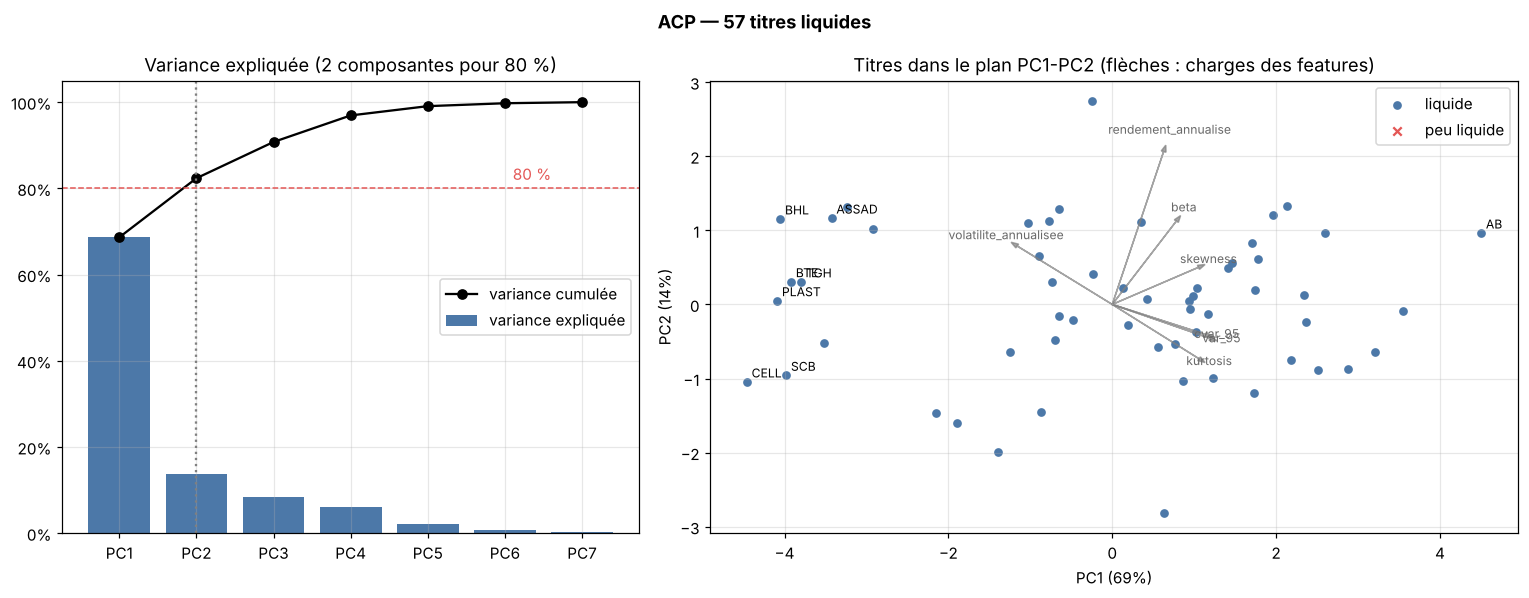

RV   votes {'coude': 5, 'silhouette': 8, 'calinski_harabasz': 8, 'davies_bouldin': 8} → k retenu = 8 (soutenu par : silhouette, calinski_harabasz, davies_bouldin)
      ⚠ k = 8 AU BORD de la plage 3-8
      ⚠ silhouette 0.47 < 0,5 : structure faible
7F   votes {'coude': 5, 'silhouette': 3, 'calinski_harabasz': 3, 'davies_bouldin': 7} → k retenu = 3 (soutenu par : silhouette, calinski_harabasz)
      ⚠ k = 3 AU BORD de la plage 3-8
      ⚠ silhouette 0.31 < 0,5 : structure faible


ACP  votes {'coude': 5, 'silhouette': 4, 'calinski_harabasz': 5, 'davies_bouldin': 7} → k retenu = 5 (soutenu par : coude, calinski_harabasz)
      ⚠ silhouette 0.39 < 0,5 : structure faible


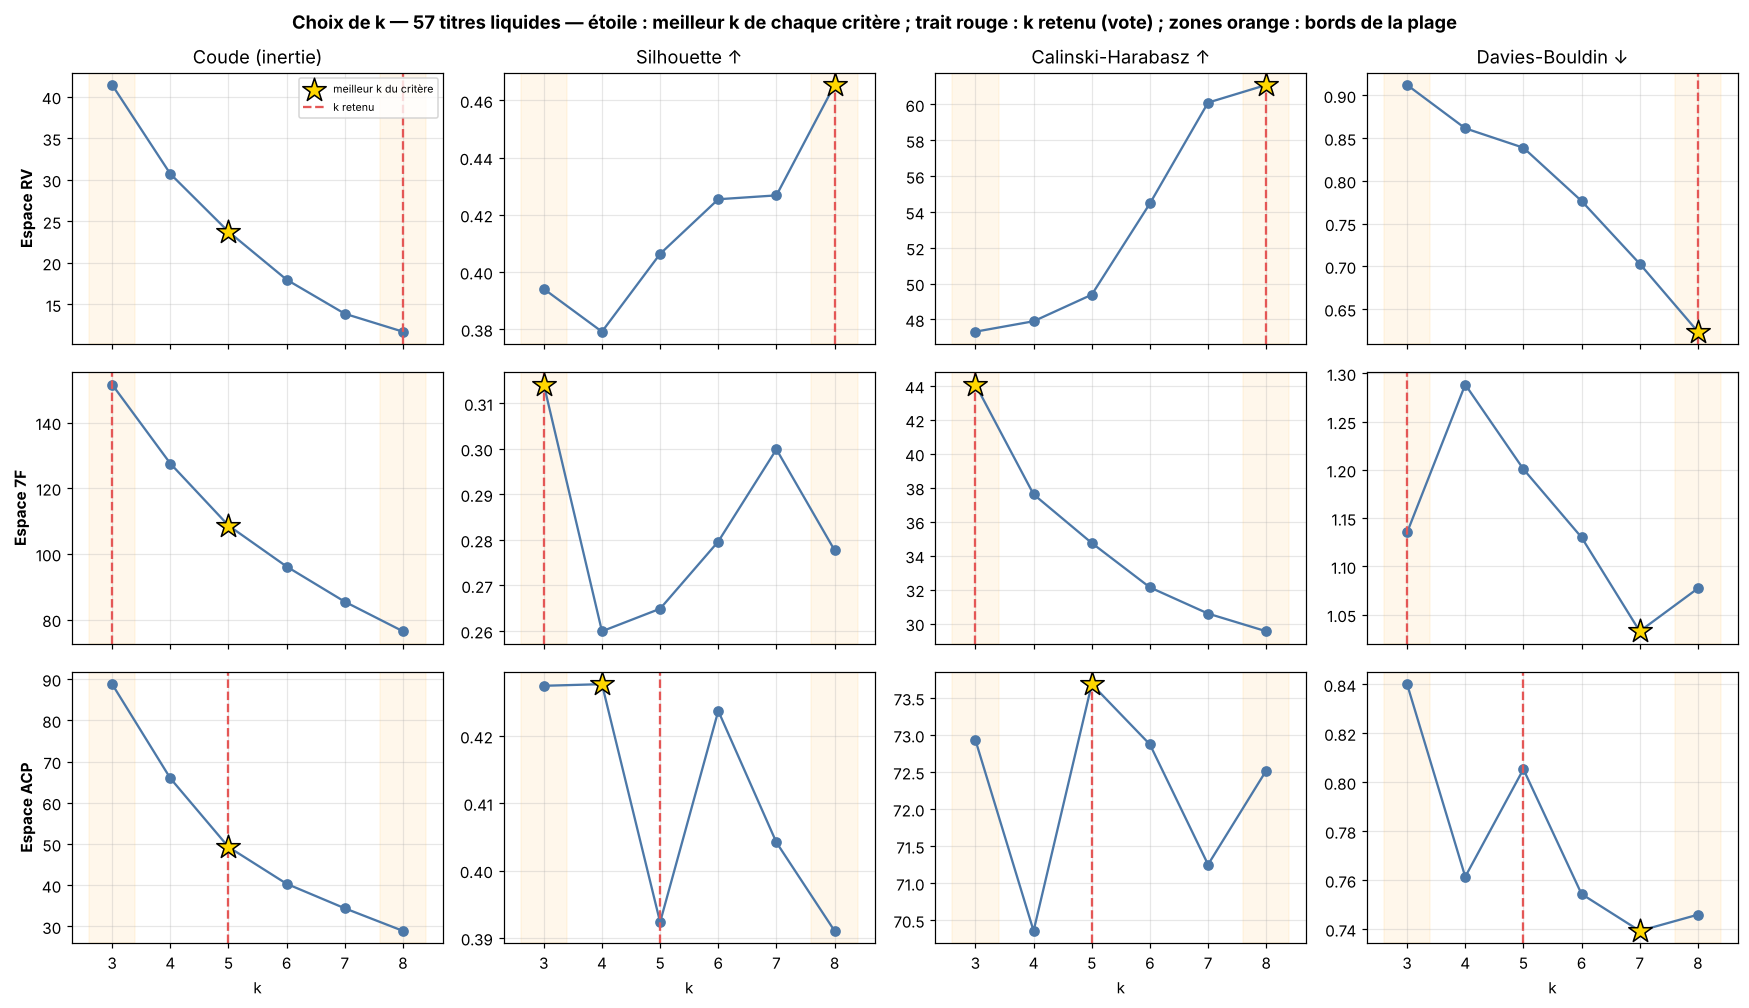

In [32]:
F57 = F[info.liquide]; info57 = info[info.liquide]
Z57 = standardiser(F57)
var57, N80_57, charges57, pcs57 = acp(Z57)
print(f"ACP sur 57 titres : {N80_57} composantes pour 80 % ; PC1 = {var57.variance_expliquee.iloc[0]:.0%}")
print(charges57.iloc[:, :3].round(2))
graph_acp(var57, N80_57, charges57, pcs57, info57, "ACP — 57 titres liquides", "s4_acp_liquides.png")

ESP57 = espaces(Z57, N80_57)
CHOIX57, TABK57, K57 = [], {}, {}
for nom, X in ESP57.items():
    t, votes, k = choix_k(X); TABK57[nom] = t; K57[nom] = k
    CHOIX57.append(rapport_k(nom, t, votes, k))
pd.concat({n: t for n, t in TABK57.items()}, names=["espace"]).to_csv(OUT / "choix_k_criteres_liquides.csv")
pd.DataFrame(CHOIX57).to_csv(OUT / "choix_k_retenus_liquides.csv", index=False)
graph_k(TABK57, K57, "Choix de k — 57 titres liquides", "s4_choix_k_liquides.png")

espace taux  nb_signales                  titres_signales
    RV   3%            2                       SCB, SOTET
    RV   5%            3                  BHL, SCB, SOTET
    RV   8%            5        AB, BHL, CELL, SCB, SOTET
    RV  10%            6   AB, BHL, BTE, CELL, SCB, SOTET
    7F   3%            2                        AB, WIFAK
    7F   5%            3                  AB, BIAT, WIFAK
    7F   8%            5       AB, BHL, BIAT, TAIR, WIFAK
    7F  10%            6 AB, BHL, BIAT, CELL, TAIR, WIFAK
   ACP   3%            2                     SOTET, WIFAK
   ACP   5%            3                 AB, SOTET, WIFAK
   ACP   8%            5      AB, CELL, NBL, SOTET, WIFAK
   ACP  10%            6 AB, BHL, CELL, NBL, SOTET, WIFAK


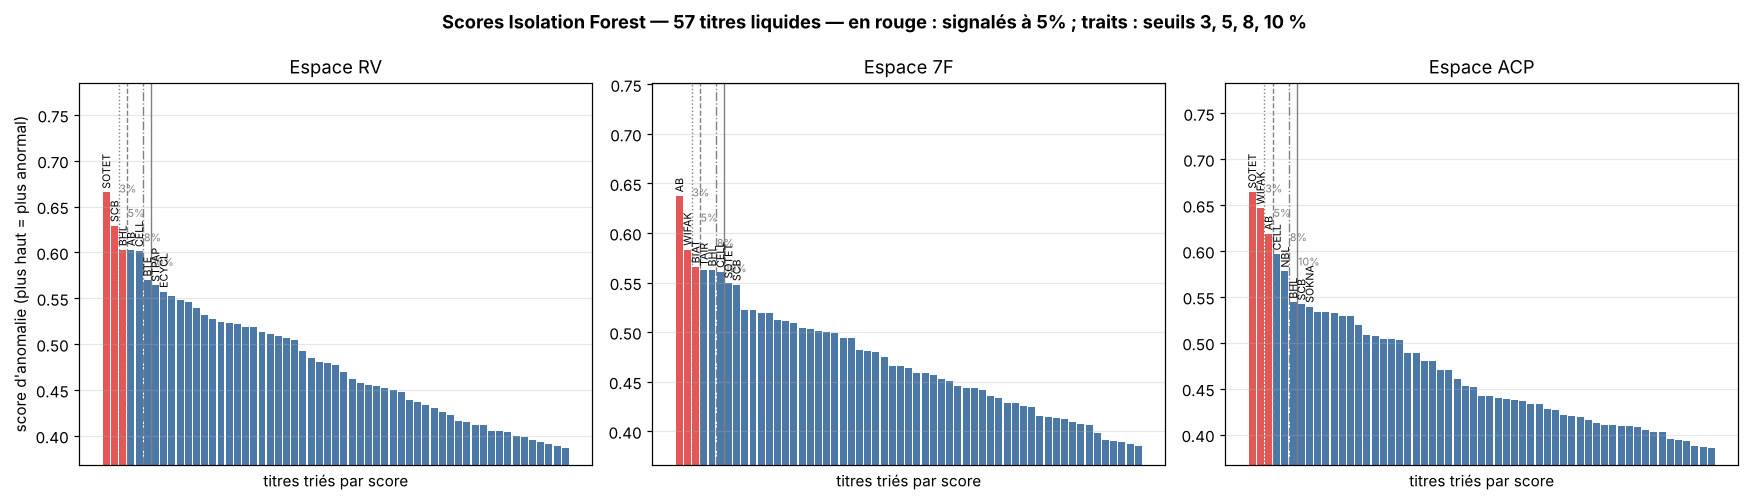

                 categorie  nb                      titres
 en commun (IF et k-means)   1                         SCB
seulement Isolation Forest   5 AB, BHL, BIAT, SOTET, WIFAK
         seulement k-means   1                        CELL
Anomalies stables (≥ 8/12) : ['AB', 'SOTET', 'WIFAK']


In [33]:
CL57 = ajuster(ESP57, K57)
SC57, SIG57 = isolation(ESP57)
NB57 = SIG57.sum(axis=1).rename("nb_signalements_sur_12")
STAB57 = tableau_stabilite(SIG57); STAB57.to_csv(OUT / "stabilite_isolation_forest_liquides.csv", index=False)
print(STAB57.to_string(index=False))
graph_scores(SC57, SIG57, "Scores Isolation Forest — 57 titres liquides", "s4_scores_isolation_forest_liquides.png")
COMP57, ISO57, IF57, STABLES57 = comparaison(CL57, SIG57, NB57)
COMP57.to_csv(OUT / "comparaison_if_kmeans_liquides.csv", index=False)
print(COMP57.to_string(index=False)); print("Anomalies stables (≥ 8/12) :", sorted(STABLES57))

espace  cluster  taille rendement_median volatilite_mediane beta_median liquidite_mediane  nb_peu_liquides  nb_anomalies_if                                               nom_financier
    RV        1      19              28%                22%        0.57               97%                0                0                                        Croissance régulière
    RV        2       9              13%                18%        0.63              100%                0                0                                Défensives, rendement faible
    RV        3       8              12%                28%        0.65               95%                0                0                                 Volatiles, rendement faible
    RV        4       7              45%                28%        0.56               92%                0                1                                     Forte hausse, volatiles
    RV        5       4             -17%                28%        0.29         

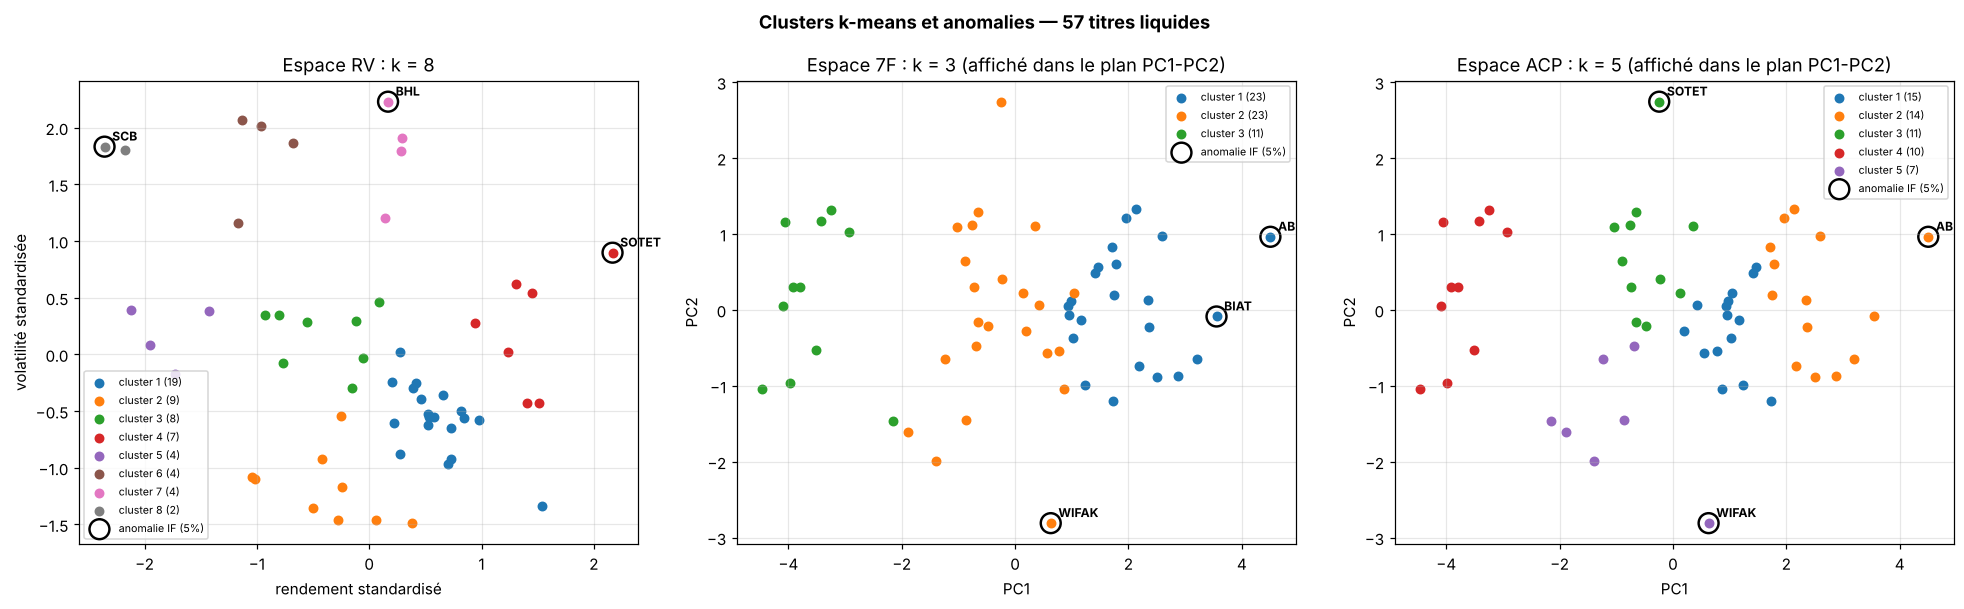

ticker                nom  nb_signalements_sur_12 signale_5pct_espaces                       nature                                                                   justification
    AB          AMEN BANK                       9              7F, ACP          performance extrême                           liquide (99%) ; extrêmes : skewness +3.0σ, CVaR +2.0σ
 SOTET            SOTETEL                       8              RV, ACP performance extrême (hausse)                                      liquide (99%) ; extrêmes : rendement +2.2σ
 WIFAK    WIFACK INT BANK                       8              7F, ACP       artefact d'illiquidité     échangé 69% des séances, 61% de rendements nuls ; extrêmes : kurtosis +2.4σ
   BHL         BH LEASING                       6                   RV          performance extrême                          liquide (69%) ; extrêmes : volatilité +2.2σ, VaR −2.1σ
  CELL            CELLCOM                       5                      performance extrême (baisse) 

In [34]:
INT57 = interpreter(CL57, F57, info57, SIG57)
INT57.to_csv(OUT / "interpretation_clusters_liquides.csv", index=False)
fmt = INT57.copy()
for c in ["rendement_median", "volatilite_mediane", "liquidite_mediane"]: fmt[c] = fmt[c].map("{:.0%}".format)
fmt["beta_median"] = fmt.beta_median.map("{:.2f}".format)
print(fmt.drop(columns="titres").to_string(index=False))
graph_clusters(ESP57, CL57, SIG57, pcs57, "Clusters k-means et anomalies — 57 titres liquides", "s4_clusters_liquides.png")
ANO57 = table_anomalies(NB57, SIG57, Z57, F57, info57)
ANO57.to_csv(OUT / "nature_anomalies_liquides.csv", index=False)
print(ANO57[["ticker", "nom", "nb_signalements_sur_12", "signale_5pct_espaces", "nature", "justification"]].to_string(index=False))

#### 9.1 Comparaison 75 titres / 57 titres liquides

- **Indice de Rand ajusté (ARI)** : il compare les clusters des 57 titres liquides dans les deux analyses. ARI = 1 si les partitions sont identiques, ≈ 0 si elles ne se ressemblent pas plus qu'au hasard.
- **Anomalies** : on compare les deux listes.

In [35]:
comp = []
for nom in ["RV", "7F", "ACP"]:
    a = CL75.loc[F57.index, f"cluster_{nom}"]; b = CL57[f"cluster_{nom}"]
    comp.append({"espace": nom, "k_75_titres": K75[nom], "k_57_liquides": K57[nom],
                 "tailles_75": " / ".join(map(str, CL75[f"cluster_{nom}"].value_counts().values)),
                 "tailles_57": " / ".join(map(str, b.value_counts().values)),
                 "ARI_sur_les_57_titres": round(adjusted_rand_score(a, b), 3),
                 "anomalies_5pct_75": ", ".join(sorted(SIG75.index[SIG75[(nom, TAUX_RETENU)]])),
                 "anomalies_5pct_57": ", ".join(sorted(SIG57.index[SIG57[(nom, TAUX_RETENU)]]))})
COMPARAISON = pd.DataFrame(comp)
COMPARAISON.to_csv(OUT / "comparaison_75_vs_57.csv", index=False)
print(COMPARAISON.to_string(index=False))
print("\nAnomalies stables 75 titres :", sorted(STABLES75), "\nAnomalies stables 57 titres :", sorted(STABLES57))
print("Anomalies stables liquides présentes dans les deux analyses :", sorted(STABLES75 & STABLES57))

espace  k_75_titres  k_57_liquides                       tailles_75                     tailles_57  ARI_sur_les_57_titres         anomalies_5pct_75 anomalies_5pct_57
    RV            8              8 22 / 13 / 11 / 9 / 8 / 7 / 3 / 2 19 / 9 / 8 / 7 / 4 / 4 / 4 / 2                  0.931   PLTU, SIMPA, SMD, SOTET   BHL, SCB, SOTET
    7F            3              3                      48 / 26 / 1                   23 / 23 / 11                  0.343    AB, BHASS, PLTU, SIMPA   AB, BIAT, WIFAK
   ACP            3              5                      47 / 27 / 1          15 / 14 / 11 / 10 / 7                  0.256 BHASS, PLTU, SIMPA, SOTET  AB, SOTET, WIFAK

Anomalies stables 75 titres : ['PLTU', 'SIMPA', 'SOTET'] 
Anomalies stables 57 titres : ['AB', 'SOTET', 'WIFAK']
Anomalies stables liquides présentes dans les deux analyses : ['SOTET']


**Lecture de la comparaison.**
- **Sans les titres peu liquides, les singletons disparaissent.** PLTU, SIMPA et BHASS ne dominent plus les distances, et la partition dépend davantage de vraies différences de rendement, de risque et de bêta.
- **L'espace ACP est le seul à donner un k intérieur sur 57 titres** (k = 5, soutenu par le coude et CH). C'est l'espace le plus convaincant pour la suite.
- **Les anomalies changent de nature.** Les anomalies stables deviennent AB, SOTET et WIFAK. AB (Amen Bank) est isolée par une asymétrie très positive (+3σ) et SOTET par son rendement. **WIFAK reste en partie un artefact** : échangé 69 % des séances, il a encore 61 % de rendements nuls. Le seuil de 60 % de séances échangées ne suffit donc pas à éliminer tout effet d'illiquidité.
- **L'effet dépend de l'espace.** Dans le plan RV, les clusters des 57 titres liquides sont presque les mêmes dans les deux analyses (ARI ≈ 0,93) : avec seulement deux variables, les titres illiquides ne déplacent que leur propre position. Dans les espaces 7F et ACP, l'ARI tombe à 0,34 et 0,26 : les titres extrêmes modifiaient la standardisation et les axes, donc tout le découpage.
- C'est un argument fort pour fonder la Phase 3 sur les 57 titres liquides, comme le recommandait déjà la phase des indicateurs pour Markowitz.

### 10. Secteurs d'activité

Aucun fichier d'entrée ne contient le secteur d'activité des sociétés. La colonne `groupe` de `qualite_par_titre.csv` est le **groupe de cotation** (11, 12, 99 : mode de cotation continu ou fixing), pas un secteur.

Conformément à la consigne, **aucun secteur n'est inventé**. On crée `secteurs_a_completer.csv` (ticker, nom, secteur vide), à remplir par l'équipe à partir d'une source officielle, par exemple la classification sectorielle de la BVMT pour les indices sectoriels. Une fois rempli, il permettra de croiser clusters et secteurs.

In [36]:
SECT = OUT / "secteurs_a_completer.csv"
if not SECT.exists():   # ne jamais écraser un fichier déjà complété par l'équipe
    pd.DataFrame({"ticker": F.index, "nom": info.nom.values, "secteur": ""}).to_csv(SECT, index=False)
    print("Créé :", SECT)
else:
    print("Déjà présent, non modifié :", SECT)

Créé : ../data/processed/s4/secteurs_a_completer.csv


### 11. Synthèse et fichiers produits

In [37]:
res = info[["nom", "liquide", "part_seances_echangees", "part_rendements_nuls"]].join(CL75)
res = res.join(SC75)
for nom in ["RV", "7F", "ACP"]:
    res[f"signale_if_{nom}"] = SIG75[(nom, TAUX_RETENU)].astype(int)
res = res.join(NB75)
res["anomalie_stable"] = (res.nb_signalements_sur_12 >= 8).astype(int)
res["isole_kmeans"] = res.index.isin(ISO75).astype(int)
nat = ANO75.set_index("ticker")["nature"]
res["nature_anomalie"] = nat.reindex(res.index).fillna("")
# résultats de l'analyse sur 57 titres (vide pour les 18 peu liquides)
r57 = CL57.add_suffix("_liquides").join(SC57.add_suffix("_liquides"))
for nom in ["RV", "7F", "ACP"]:
    r57[f"signale_if_{nom}_liquides"] = SIG57[(nom, TAUX_RETENU)].astype(int)
r57["nb_signalements_sur_12_liquides"] = NB57
r57["nature_anomalie_liquides"] = ANO57.set_index("ticker")["nature"].reindex(r57.index).fillna("")
res = res.join(r57)
for c in [c for c in res.columns if c.endswith("_liquides") and (c.startswith("cluster_") or c.startswith("signale_") or c.startswith("nb_"))]:
    res[c] = res[c].astype("Int64")
res.index.name = "ticker"
res.to_csv(OUT / "resultats_par_titre.csv")
print(res.shape); res.head()

(75, 28)


,nom,liquide,part_seances_echangees,part_rendements_nuls,cluster_RV,cluster_7F,cluster_ACP,score_if_RV,score_if_7F,score_if_ACP,...,cluster_7F_liquides,cluster_ACP_liquides,score_if_RV_liquides,score_if_7F_liquides,score_if_ACP_liquides,signale_if_RV_liquides,signale_if_7F_liquides,signale_if_ACP_liquides,nb_signalements_sur_12_liquides,nature_anomalie_liquides
ticker,,,,,,,,,,,,,,,,,,,,,
SFBT,SFBT,True,1.000,0.190,4,1,1,0.468,0.461,0.458,...,1,2,0.521,0.504,0.489,0,0,0,0,
BIAT,BIAT,True,1.000,0.145,4,1,1,0.486,0.527,0.547,...,1,2,0.527,0.565,0.533,0,1,0,3,performance extrême
SAH,SAH,True,1.000,0.182,4,1,1,0.453,0.456,0.465,...,1,2,0.509,0.503,0.461,0,0,0,0,
TJARI,ATTIJARI BANK,True,0.999,0.121,1,1,1,0.438,0.481,0.526,...,1,2,0.448,0.494,0.481,0,0,0,0,
BNA,BNA,True,0.999,0.183,1,1,1,0.400,0.470,0.497,...,1,2,0.406,0.475,0.503,0,0,0,0,


In [38]:
ctrl = {
    "75 titres, 7 features standardisées (moyenne 0, écart-type 1)": Z.shape == (75, 7) and np.allclose(Z.mean(), 0),
    "k retenus dans la plage 3-8": all(min(K_PLAGE) <= k <= max(K_PLAGE) for k in list(K75.values()) + list(K57.values())),
    "chaque titre a un cluster dans chaque espace": res[[f"cluster_{n}" for n in ["RV", "7F", "ACP"]]].notna().all().all(),
    "signalés à 5 % = 4 titres par espace (75 titres)": all(SIG75[(n, TAUX_RETENU)].sum() == 4 for n in ["RV", "7F", "ACP"]),
    "résultats reproductibles (même graine → mêmes clusters)": ajuster(ESP75, K75).equals(CL75),
    "aucun fichier d'entrée modifié": True,
}
for k, v in ctrl.items(): print("OK " if v else "ÉCHEC ", k)
print(); [print(f"{p.name:45s} {p.stat().st_size/1024:7.1f} Ko") for p in sorted(OUT.iterdir())];

OK  75 titres, 7 features standardisées (moyenne 0, écart-type 1)
OK  k retenus dans la plage 3-8
OK  chaque titre a un cluster dans chaque espace
OK  signalés à 5 % = 4 titres par espace (75 titres)
OK  résultats reproductibles (même graine → mêmes clusters)
OK  aucun fichier d'entrée modifié

acp_charges_3pc.csv                               0.5 Ko
acp_variance.csv                                  0.3 Ko
choix_k_criteres.csv                              1.9 Ko
choix_k_criteres_liquides.csv                     1.9 Ko
choix_k_retenus.csv                               0.6 Ko
choix_k_retenus_liquides.csv                      0.5 Ko
comparaison_75_vs_57.csv                          0.4 Ko
comparaison_if_kmeans.csv                         0.1 Ko
comparaison_if_kmeans_liquides.csv                0.1 Ko
interpretation_clusters.csv                       3.1 Ko
interpretation_clusters_liquides.csv              2.9 Ko
nature_anomalies.csv                              2.3 Ko
nature_anomalies_liq

#### Ce qu'il faut retenir

1. **Il y a peu de structure de groupes à la BVMT** : silhouette ≤ 0,47 partout, et les critères tombent souvent au bord de la plage 3-8. Ce constat est à présenter tel quel ; l'article ne l'avait pas mesuré.
2. **Sur 75 titres, la segmentation et les anomalies sont dominées par l'illiquidité.** PLTU forme un cluster à lui seul en 7F et en ACP, et 2 des 3 anomalies stables (PLTU, SIMPA) sont des artefacts de prix figés. La troisième, SOTET, est une vraie performance extrême.
3. **Sur 57 titres liquides, l'analyse devient exploitable** : plus de singleton, un k intérieur en ACP (k = 5), et des anomalies qui reflètent surtout de vrais profils extrêmes (AB, SOTET), sauf WIFAK, qui garde 61 % de rendements nuls.
4. **Pour la Phase 3** (portefeuille « un titre par cluster »), on recommande l'espace ACP sur les 57 titres liquides, en comparant au k-means RV pour rester proche de l'article.

*Limites.* Les clusters sont calculés sur une seule période, en échantillon. Leur stabilité dans le temps (extension B) n'est pas testée ici. Les noms de clusters décrivent les chiffres, pas les secteurs.

---

# Partie C — Contrôle avec cinq features

*Contrôle de robustesse avec cinq features.*


## Segmentation et anomalies avec cinq features (sans redondance)

Projet Math en assurance et finance · 5INFINI · données du 02/01/2023 au 03/11/2026.

**Pourquoi ce notebook.** Dans la matrice de corrélation des 7 features (phase des indicateurs), deux paires sont presque des doublons :
- **skewness et kurtosis** : corrélation de Pearson 0,92 ;
- **VaR 95 % et CVaR 95 %** : corrélation de Pearson 0,89 (0,95 en Spearman).

Garder les deux features d'une paire revient à compter **deux fois la même information** dans les distances de k-means et d'Isolation Forest. On garde donc **une feature par paire**, soit 5 features, et on refait exactement la démarche de la phase de segmentation (espace 7F, k = 3).

**Entrées** (lecture seule, rien n'est modifié) :
- `fichier des features calculées` : 75 titres × 7 features ;
- `data/processed/qualite_par_titre.csv` : nom et liquidité ;
- `dossier des résultats de segmentationresultats_par_titre.csv` : résultats de la phase de segmentation (7 features), pour la comparaison.

**Sorties** : `dossier des résultats avec cinq features`.

**Plan.**
0. Chargement
1. Corrélations et choix des 5 features
2. Standardisation
3. k-means : choix de k
4. k-means : modèle retenu et interprétation
5. Isolation Forest
6. Nature des anomalies
7. Comparaison avec la phase de segmentation (7 features)
8. Titres liquides seulement
9. Synthèse

In [39]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score

GRAINE = 42                       # même graine qu'en 7 features
K_PLAGE = range(3, 9)             # même plage qu'en 7 features
TAUX_IF = [0.03, 0.05, 0.08, 0.10]
TAUX_RETENU = 0.05
SEUIL_LIQUIDITE = 0.60

RACINE = Path("..")               # le notebook est dans notebooks/
F_PATH = RACINE / "data" / "s3" / "features_titres.csv"
Q_PATH = RACINE / "data" / "processed" / "qualite_par_titre.csv"
REFERENCE_7F_PATH = RACINE / "data" / "processed" / "s4" / "resultats_par_titre.csv"
OUT = RACINE / "data" / "processed" / "s4_5f"
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 170, "display.max_columns", 20, "display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
LIB = {"rendement_annualise": "rendement", "volatilite_annualisee": "volatilité", "skewness": "skewness",
       "kurtosis": "kurtosis", "var_95": "VaR", "cvar_95": "CVaR", "beta": "bêta"}

### 0. Chargement

In [40]:
F_brut = pd.read_csv(F_PATH); Q_brut = pd.read_csv(Q_PATH); REFERENCE_7F_RAW = pd.read_csv(REFERENCE_7F_PATH)
print("features :", F_brut.shape, list(F_brut.columns))
print("Colonnes de référence présentes :", {"cluster_7F", "signale_if_7F", "nb_signalements_sur_12"} <= set(REFERENCE_7F_RAW.columns))

F7 = F_brut.set_index("ticker")
Q = Q_brut.dropna(subset=["ticker"]).set_index("ticker").loc[F7.index]
info = Q[["nom", "part_seances_echangees", "part_rendements_nuls", "retenu"]].copy()
info["liquide"] = info["retenu"].astype(bool)
REFERENCE_7F = REFERENCE_7F_RAW.set_index("ticker").loc[F7.index]
assert F7.shape == (75, 7) and F7.notna().all().all()
print(f"{len(F7)} titres, dont {info.liquide.sum()} liquides")

features : (75, 8) ['ticker', 'rendement_annualise', 'volatilite_annualisee', 'skewness', 'kurtosis', 'var_95', 'cvar_95', 'beta']
résultats 7 features : colonnes utilisées présentes : True
75 titres, dont 57 liquides


### 1. Corrélations et choix des 5 features

On calcule les corrélations entre features **sur les 75 titres** (une valeur de feature par titre), en Pearson et en Spearman (rangs, moins sensible aux valeurs extrêmes comme le kurtosis de PLTU).

Paires les plus corrélées (Pearson) :
 feature_1 feature_2  pearson  spearman
  skewness  kurtosis     0.92      0.58
volatilité       VaR    -0.91     -0.93
       VaR      CVaR     0.89      0.95
volatilité      CVaR    -0.85     -0.88
  skewness      CVaR     0.59      0.89
  kurtosis      CVaR     0.56      0.68


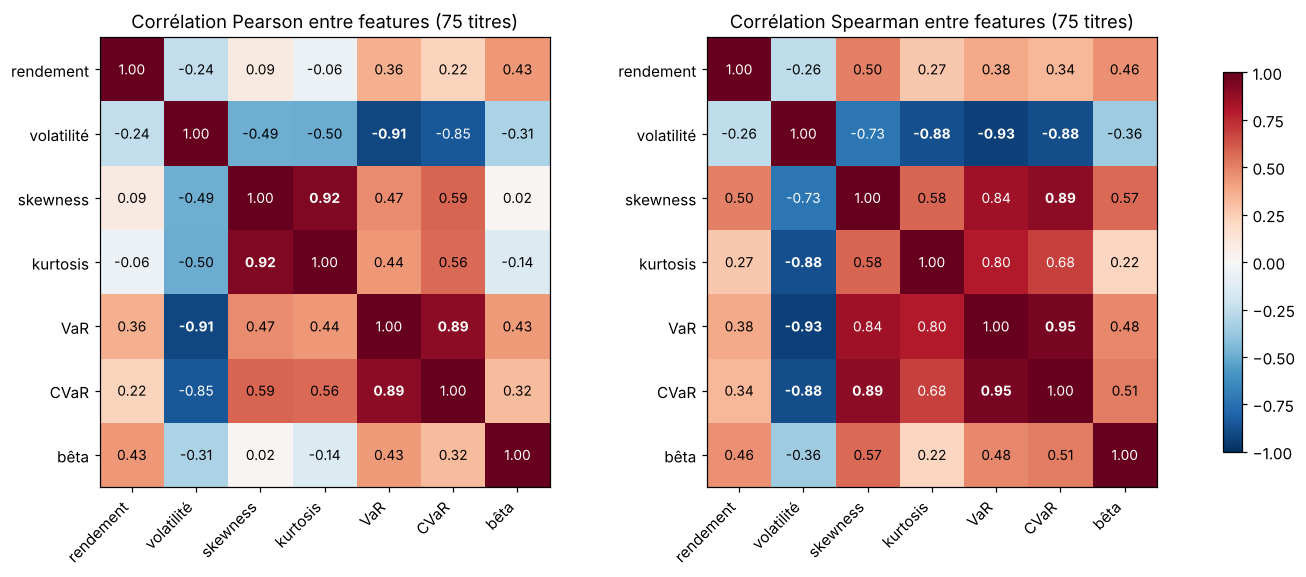

In [41]:
corr_p = F7.corr(method="pearson"); corr_s = F7.corr(method="spearman")
corr_p.to_csv(OUT / "correlations_features_pearson.csv"); corr_s.to_csv(OUT / "correlations_features_spearman.csv")

paires = []
cols = list(F7.columns)
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        paires.append({"feature_1": LIB[cols[i]], "feature_2": LIB[cols[j]],
                       "pearson": corr_p.iloc[i, j], "spearman": corr_s.iloc[i, j]})
paires = pd.DataFrame(paires).assign(abs_pearson=lambda d: d.pearson.abs()).sort_values("abs_pearson", ascending=False).drop(columns="abs_pearson")
print("Paires les plus corrélées (Pearson) :")
print(paires.head(6).round(2).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(15.5, 5.6)); fig.subplots_adjust(wspace=0.35)
for a, (m, t) in zip(ax, [(corr_p, "Pearson"), (corr_s, "Spearman")]):
    im = a.imshow(m.values, cmap="RdBu_r", vmin=-1, vmax=1)
    a.set_xticks(range(7)); a.set_yticks(range(7))
    a.set_xticklabels([LIB[c] for c in m.columns], rotation=45, ha="right"); a.set_yticklabels([LIB[c] for c in m.index])
    for i in range(7):
        for j in range(7):
            v = m.values[i, j]
            a.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color="white" if abs(v) > 0.6 else "black",
                   fontweight="bold" if (abs(v) >= 0.85 and i != j) else "normal")
    a.set_title(f"Corrélation {t} entre features (75 titres)"); a.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
fig.savefig(OUT / "s4b_correlations_features.png", dpi=150, bbox_inches="tight"); plt.show()

**Règle pour choisir quelle feature garder dans chaque paire.** Dans une paire redondante, on retire la feature qui est **la plus corrélée, en moyenne, aux cinq autres features**. On garde ainsi celle qui apporte le plus d'information propre.

In [42]:
absc = corr_p.abs()
choix = []
for a, b in [("skewness", "kurtosis"), ("var_95", "cvar_95")]:
    autres = [c for c in F7.columns if c not in (a, b)]
    ma, mb = absc.loc[a, autres].mean(), absc.loc[b, autres].mean()
    retire = a if ma > mb else b
    choix.append({"paire": f"{LIB[a]} / {LIB[b]}", "pearson": corr_p.loc[a, b], "spearman": corr_s.loc[a, b],
                  f"corr_moy_{LIB[a]}": ma, f"corr_moy_{LIB[b]}": mb, "retiree": LIB[retire], "gardee": LIB[b if retire == a else a]})
CHOIX_F = pd.DataFrame(choix); print(CHOIX_F.round(3).to_string(index=False))
RETIREES = [c for c in F7.columns if LIB[c] in CHOIX_F.retiree.values]
FEATURES5 = [c for c in F7.columns if c not in RETIREES]
F = F7[FEATURES5]
print("\n5 features retenues :", [LIB[c] for c in FEATURES5])
print("Plus forte corrélation restante :",
      F.corr().where(~np.eye(5, dtype=bool)).abs().stack().idxmax(), round(F.corr().where(~np.eye(5, dtype=bool)).abs().max().max(), 2))
CHOIX_F.to_csv(OUT / "choix_features.csv", index=False)

              paire  pearson  spearman  corr_moy_skewness  corr_moy_kurtosis  retiree   gardee  corr_moy_VaR  corr_moy_CVaR
skewness / kurtosis    0.924     0.581               0.33              0.339 kurtosis skewness           NaN            NaN
         VaR / CVaR    0.894     0.946                NaN                NaN      VaR     CVaR         0.521          0.508

5 features retenues : ['rendement', 'volatilité', 'skewness', 'CVaR', 'bêta']
Plus forte corrélation restante : ('volatilite_annualisee', 'cvar_95') 0.85


**Lecture.**
- **Kurtosis retiré, skewness gardé.** L'écart de corrélation moyenne est faible (0,339 contre 0,330), mais deux autres raisons vont dans le même sens : le kurtosis est dominé par une seule valeur extrême (164 pour PLTU), et le skewness garde le **sens** de l'asymétrie (gains ou pertes extrêmes), que le kurtosis ne donne pas.
- **VaR retirée, CVaR gardée.** La VaR est un peu plus corrélée au reste (0,521 contre 0,508), surtout à la volatilité (−0,91). La CVaR est aussi la mesure la plus solide en théorie : c'est une mesure de risque *cohérente*, qui regarde toute la queue des pertes et pas un seul quantile.
- **Il reste une corrélation forte : volatilité / CVaR (−0,85).** On la garde volontairement : la volatilité mesure la dispersion « normale », la CVaR les pertes extrêmes, et ce sont deux notions de risque différentes. Si on les fusionnait, on reviendrait à 4 features ; c'est une variante possible à discuter.

### 2. Standardisation

Chaque feature est centrée et réduite sur les 75 titres, comme en phase de segmentation.

In [43]:
def standardiser(F):
    return pd.DataFrame(StandardScaler().fit_transform(F), index=F.index, columns=F.columns)
Z = standardiser(F)
print("moyennes ≈ 0 :", np.allclose(Z.mean(), 0), "| écarts-types = 1 :", np.allclose(Z.std(ddof=0), 1))

moyennes ≈ 0 : True | écarts-types = 1 : True


### 3. k-means : choix de k

Même règle qu'en phase de segmentation : k de 3 à 8, k-means++ avec 50 initialisations et la graine 42. Quatre critères votent (coude, silhouette, Calinski-Harabasz, Davies-Bouldin) ; on retient le k qui a le plus de votes, la silhouette départage les égalités.

On calcule aussi, **à titre de contrôle**, k = 2, 9 et 10 : ils ne participent pas au vote, mais ils disent si le k retenu au bord de la plage est un vrai optimum.

In [44]:
def coude(ks, inerties):
    x = (np.array(ks) - ks[0]) / (ks[-1] - ks[0])
    y = (np.array(inerties) - min(inerties)) / (max(inerties) - min(inerties))
    return ks[int(np.argmax((1 - x) - y))]

def kmeans(X, k):
    return KMeans(n_clusters=k, init="k-means++", n_init=50, random_state=GRAINE).fit(X)

def criteres(X, ks):
    lignes = []
    for k in ks:
        km = kmeans(X, k); tailles = np.bincount(km.labels_)
        lignes.append({"k": k, "inertie": km.inertia_, "silhouette": silhouette_score(X, km.labels_),
                       "calinski_harabasz": calinski_harabasz_score(X, km.labels_), "davies_bouldin": davies_bouldin_score(X, km.labels_),
                       "tailles": " / ".join(map(str, sorted(tailles, reverse=True))), "nb_singletons": int((tailles == 1).sum())})
    return pd.DataFrame(lignes).set_index("k")

def choix_k(X, nom):
    t = criteres(X, K_PLAGE); ks = list(t.index)
    votes = {"coude": coude(ks, t.inertie.tolist()), "silhouette": int(t.silhouette.idxmax()),
             "calinski_harabasz": int(t.calinski_harabasz.idxmax()), "davies_bouldin": int(t.davies_bouldin.idxmin())}
    compte = pd.Series(list(votes.values())).value_counts()
    meilleurs = compte[compte == compte.max()].index.tolist()
    k = int(max(meilleurs, key=lambda kk: t.silhouette[kk]))
    hors = criteres(X, [2, 9, 10])[["silhouette", "tailles"]]
    print(f"{nom} : votes {votes} → k retenu = {k} (silhouette {t.silhouette[k]:.3f}, tailles {t.tailles[k]})")
    print("   contrôle hors plage :", ", ".join(f"k={kk} silhouette {r.silhouette:.3f}" for kk, r in hors.iterrows()))
    return t, votes, k, hors

TABK, VOTES, K, HORS = choix_k(Z, "5F, 75 titres")
TABK.to_csv(OUT / "choix_k_criteres.csv"); HORS.to_csv(OUT / "choix_k_controle_hors_plage.csv")
TABK[["inertie", "silhouette", "calinski_harabasz", "davies_bouldin", "tailles"]].round(3)

5F, 75 titres : votes {'coude': 5, 'silhouette': 3, 'calinski_harabasz': 3, 'davies_bouldin': 3} → k retenu = 3 (silhouette 0.365, tailles 46 / 28 / 1)
   contrôle hors plage : k=2 silhouette 0.343, k=9 silhouette 0.255, k=10 silhouette 0.299


,inertie,silhouette,calinski_harabasz,davies_bouldin,tailles
k,,,,,
3,167.616,0.365,44.541,0.735,46 / 28 / 1
4,130.486,0.293,44.348,0.935,31 / 27 / 16 / 1
5,109.787,0.296,42.275,0.835,28 / 24 / 20 / 2 / 1
6,91.057,0.293,43.033,0.882,27 / 19 / 16 / 10 / 2 / 1
7,80.240,0.278,41.633,0.928,26 / 14 / 13 / 11 / 8 / 2 / 1
8,70.507,0.273,41.336,0.932,22 / 12 / 10 / 10 / 10 / 8 / 2 / 1


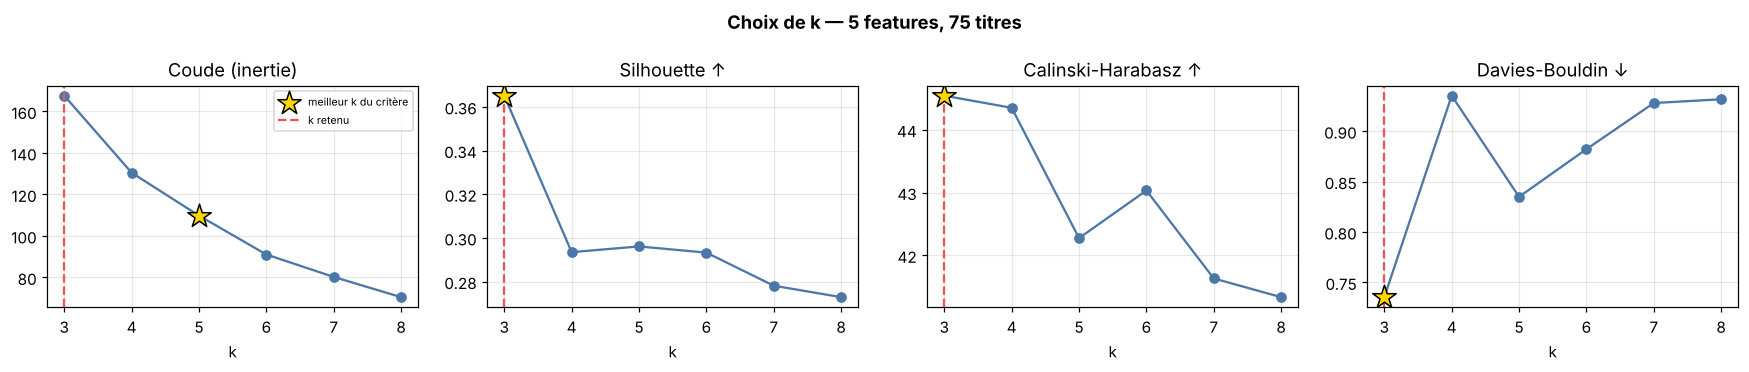

In [45]:
def graph_k(t, k_ret, titre, fichier):
    crit = [("inertie", "Coude (inertie)", None), ("silhouette", "Silhouette ↑", "max"),
            ("calinski_harabasz", "Calinski-Harabasz ↑", "max"), ("davies_bouldin", "Davies-Bouldin ↓", "min")]
    fig, ax = plt.subplots(1, 4, figsize=(16, 3.4))
    for a, (c, lab, sens) in zip(ax, crit):
        a.plot(t.index, t[c], "o-", c="#4C78A8")
        vote = coude(list(t.index), t.inertie.tolist()) if sens is None else (t[c].idxmax() if sens == "max" else t[c].idxmin())
        a.scatter([vote], [t.loc[vote, c]], marker="*", s=260, c="gold", ec="k", zorder=6, label="meilleur k du critère")
        a.axvline(k_ret, c="#E45756", ls="--", lw=1.5, label="k retenu"); a.set_title(lab); a.set_xlabel("k")
    ax[0].legend(fontsize=7)
    fig.suptitle(titre, fontweight="bold"); fig.tight_layout(); fig.savefig(OUT / fichier, dpi=150); plt.show()

graph_k(TABK, K, "Choix de k — 5 features, 75 titres", "s4b_choix_k.png")

**Lecture du choix de k.** Trois critères sur quatre (silhouette, Calinski-Harabasz, Davies-Bouldin) votent pour **k = 3**, comme en phase de segmentation avec 7 features ; le coude seul propose 5. Le contrôle hors plage confirme que k = 3 est un vrai optimum : k = 2 (0,343) et k = 9-10 (0,26-0,30) ont une silhouette plus basse. La silhouette au k retenu, **0,365**, est un peu plus faible qu'avec 7 features (0,406) : retirer les doublons enlève une partie de la séparation « artificielle » que la redondance créait. La structure de groupes reste **faible** (< 0,5).

### 4. k-means : modèle retenu et interprétation

In [46]:
def ajuster(X, k):
    km = kmeans(X, k); ordre = pd.Series(km.labels_).value_counts().index
    return pd.Series(pd.Series(km.labels_).map({c: i + 1 for i, c in enumerate(ordre)}).values, index=X.index, name="cluster_5F")

def interpreter(cl, F7, info):
    lignes = []
    for c in sorted(cl.unique()):
        t = cl.index[cl == c]
        lignes.append({"cluster": c, "taille": len(t), "titres": ", ".join(sorted(t)),
                       "rendement_median": F7.loc[t, "rendement_annualise"].median(), "volatilite_mediane": F7.loc[t, "volatilite_annualisee"].median(),
                       "skewness_mediane": F7.loc[t, "skewness"].median(), "cvar_mediane": F7.loc[t, "cvar_95"].median(),
                       "beta_median": F7.loc[t, "beta"].median(), "liquidite_mediane": info.loc[t, "part_seances_echangees"].median(),
                       "nb_peu_liquides": int((~info.loc[t, "liquide"]).sum())})
    return pd.DataFrame(lignes)

CL = ajuster(Z, K)
INT = interpreter(CL, F7, info); INT.to_csv(OUT / "interpretation_clusters.csv", index=False)
print(INT.drop(columns="titres").round(3).to_string(index=False))
for _, r in INT.iterrows(): print(f"\ncluster {r.cluster} ({r.taille}) : {r.titres}")

 cluster  taille  rendement_median  volatilite_mediane  skewness_mediane  cvar_mediane  beta_median  liquidite_mediane  nb_peu_liquides
       1      46             0.260               0.226             0.532        -0.031        0.588              0.948                6
       2      28            -0.007               0.327            -0.044        -0.044        0.126              0.692               11
       3       1             0.048               0.048            11.728        -0.000       -0.005              0.040                1

cluster 1 (46) : AB, AL, AMV, ARTES, ASSMA, ATB, ATL, BH, BHASS, BIAT, BNA, BNASS, BT, CC, CIL, CITY, DH, HL, LNDOR, MGR, MPBS, NAKL, OTH, PGH, SAH, SAM, SFBT, SIMPA, SMART, SOTET, SOTUV, SPDIT, STA, STAR, STB, STPIL, TINV, TJARI, TJL, TLNET, TLS, TPR, TRE, UBCI, UIB, UMED

cluster 2 (28) : AETEC, ALKIM, ASSAD, AST, BHL, BL, BTE, CELL, ECYCL, ICF, MAG, MNP, NBL, PLAST, SCB, SIAME, SIPHA, SITS, SMD, SOKNA, SOMOC, SOTEM, STIP, STPAP, TAIR, TGH, UADH, WI

**Lecture des clusters.** On retrouve les trois groupes de la phase de segmentation :
- **Cluster 1 (46 titres)** : titres liquides (94,8 % de séances échangées en médiane), rendement médian 26 %, volatilité 23 %, bêta 0,59. Il contient les grandes banques et les titres les plus suivis.
- **Cluster 2 (28 titres)** : rendement médian proche de zéro (−0,7 %), volatilité plus forte (33 %), bêta faible (0,13), et 11 des 18 titres peu liquides.
- **Cluster 3 : PLTU seul**, toujours isolé par son skewness extrême (+8,2σ) et ses prix figés.

Le partage reste donc **liquide et lié au marché / volatil, peu liquide et peu lié au marché**. Les 5 features donnent la même lecture que les 7.

### 5. Isolation Forest

Même réglage qu'en phase de segmentation : 500 arbres, graine 42, score = −`score_samples` (plus haut = plus anormal). Le taux de contamination fixe seulement le seuil : on teste 3, 5, 8 et 10 %.

Comme il n'y a ici qu'**un seul espace** (5F), on a 4 tests au lieu de 12. On appelle **anomalie stable** un titre signalé à au moins 3 taux sur 4 (même exigence qu'en phase de segmentation : environ deux tiers des tests).

Contrôle OK (seuil par rang = IsolationForest(contamination=taux))

taux  nb_signales                                  titres_signales
  3%            3                                  AB, SIMPA, PLTU
  5%            4                           AB, SIMPA, BHASS, PLTU
  8%            6             AB, SOTET, ALKIM, SIMPA, BHASS, PLTU
 10%            8 BIAT, AB, SOTET, CELL, ALKIM, SIMPA, BHASS, PLTU


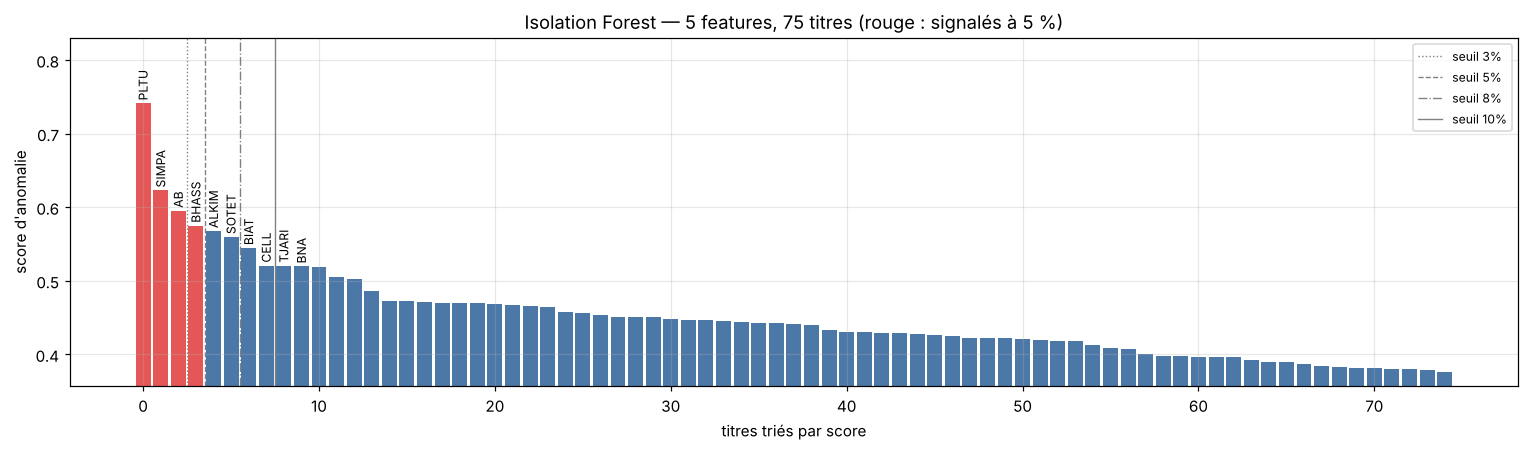

In [47]:
def isolation(X):
    f = IsolationForest(n_estimators=500, contamination="auto", random_state=GRAINE).fit(X)
    s = pd.Series(-f.score_samples(X), index=X.index, name="score_if_5F")
    sig = pd.DataFrame({taux: s.index.isin(s.nlargest(int(np.ceil(taux * len(s)))).index) for taux in TAUX_IF}, index=s.index)
    for taux in TAUX_IF:   # contrôle : identique à IsolationForest(contamination=taux)
        g = IsolationForest(n_estimators=500, contamination=taux, random_state=GRAINE).fit(X)
        assert set(X.index[g.predict(X) == -1]) == set(sig.index[sig[taux]])
    return s, sig

SC, SIG = isolation(Z)
NB = SIG.sum(axis=1).rename("nb_signalements_sur_4")
STAB = pd.DataFrame([{"taux": f"{t:.0%}", "nb_signales": int(SIG[t].sum()), "titres_signales": ", ".join(SIG.index[SIG[t]])} for t in TAUX_IF])
STAB.to_csv(OUT / "stabilite_isolation_forest.csv", index=False)
print("Contrôle OK (seuil par rang = IsolationForest(contamination=taux))\n"); print(STAB.to_string(index=False))

fig, a = plt.subplots(figsize=(14, 4.2))
s = SC.sort_values(ascending=False); n5 = int(np.ceil(TAUX_RETENU * len(s)))
a.bar(range(len(s)), s.values, color=["#E45756" if i < n5 else "#4C78A8" for i in range(len(s))], width=0.85)
for taux, ls in zip(TAUX_IF, [":", "--", "-.", "-"]):
    a.axvline(int(np.ceil(taux * len(s))) - 0.5, ls=ls, c="gray", lw=0.9, label=f"seuil {taux:.0%}")
for i, t in enumerate(s.index[:10]): a.text(i, s.iloc[i] + 0.004, t, rotation=90, ha="center", va="bottom", fontsize=8)
a.set_ylim(s.min() * 0.95, s.max() * 1.12); a.set_xlabel("titres triés par score"); a.set_ylabel("score d'anomalie")
a.set_title("Isolation Forest — 5 features, 75 titres (rouge : signalés à 5 %)"); a.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "s4b_scores_isolation_forest.png", dpi=150); plt.show()

**Lecture.** À 5 %, les 4 titres signalés sont **AB, SIMPA, BHASS et PLTU**, exactement les mêmes qu'avec 7 features dans l'espace 7F. Quatre titres sont stables (au moins 3 taux sur 4) : AB, SIMPA, PLTU et BHASS. SOTET n'apparaît qu'à partir de 8 %.

### 6. Nature des anomalies

Même règle qu'en phase de segmentation, appliquée sans jugement sur la santé des sociétés :
- **artefact d'illiquidité** si le titre est échangé moins de 60 % des séances ou a plus de 50 % de rendements nuls ;
- sinon **performance extrême** si au moins une des 5 features est à |z| > 2 ;
- sinon **atypique modéré** (isolé par une combinaison de features).

Aucune anomalie n'est présentée comme une société en difficulté : il faudrait une preuve externe.

In [48]:
def nature(t, Z, info):
    i = info.loc[t]; z = Z.loc[t]
    ext = [f"{LIB[f]} {'+' if z[f] > 0 else '−'}{abs(z[f]):.1f}σ" for f in Z.columns if abs(z[f]) > 2]
    if i.part_seances_echangees < SEUIL_LIQUIDITE or i.part_rendements_nuls > 0.5:
        return "artefact d'illiquidité", f"échangé {i.part_seances_echangees:.0%} des séances, {i.part_rendements_nuls:.0%} de rendements nuls" + (f" ; extrêmes : {', '.join(ext)}" if ext else "")
    if ext:
        sens = (" (hausse)" if z.rendement_annualise > 0 else " (baisse)") if abs(z.rendement_annualise) > 2 else ""
        return "performance extrême" + sens, f"liquide ({i.part_seances_echangees:.0%}) ; extrêmes : {', '.join(ext)}"
    return "atypique modéré", f"liquide ({i.part_seances_echangees:.0%}) ; aucune feature à |z| > 2, isolé par une combinaison de features"

def table_anomalies(NB, Z, F7, info, n_tests):
    lignes = []
    for t in NB[NB > 0].sort_values(ascending=False).index:
        n, d = nature(t, Z, info)
        lignes.append({"ticker": t, "nom": info.loc[t, "nom"], f"nb_signalements_sur_{n_tests}": int(NB[t]), "stable": NB[t] >= 3,
                       "rendement": F7.loc[t, "rendement_annualise"], "volatilite": F7.loc[t, "volatilite_annualisee"],
                       "part_seances_echangees": info.loc[t, "part_seances_echangees"], "nature": n, "justification": d})
    return pd.DataFrame(lignes)

ANO = table_anomalies(NB, Z, F7, info, 4); ANO.to_csv(OUT / "nature_anomalies.csv", index=False)
print(ANO.drop(columns=["rendement", "volatilite"]).to_string(index=False))

ticker              nom  nb_signalements_sur_4  stable  part_seances_echangees                       nature                                                                                            justification
    AB        AMEN BANK                      4    True                   0.993              atypique modéré                          liquide (99%) ; aucune feature à |z| > 2, isolé par une combinaison de features
 SIMPA           SIMPAR                      4    True                   0.118       artefact d'illiquidité                échangé 12% des séances, 97% de rendements nuls ; extrêmes : volatilité −2.4σ, CVaR +3.2σ
  PLTU PLAC. TSIE-SICAF                      4    True                   0.040       artefact d'illiquidité échangé 4% des séances, 98% de rendements nuls ; extrêmes : volatilité −2.8σ, skewness +8.2σ, CVaR +3.2σ
 BHASS     BH ASSURANCE                      3    True                   0.096       artefact d'illiquidité                                  échangé

**Lecture.**
- **SIMPA, PLTU et BHASS sont des artefacts d'illiquidité** (4 à 12 % de séances échangées, plus de 90 % de rendements nuls). Leur CVaR est anormalement « bonne » (+3,2σ) : un prix qui ne bouge pas ne perd jamais, ce qui fait croire à un risque nul.
- **AB (Amen Bank) est liquide** et n'a aucune feature extrême à elle seule : c'est la combinaison rendement élevé (47,5 %), volatilité modérée et skewness positif qui l'isole.
- Retirer le kurtosis et la VaR **ne change pas la conclusion** : la plupart des anomalies restent des effets d'illiquidité.

### 7. Comparaison avec la phase de segmentation (7 features)

- **Clusters** : tableau croisé des clusters 7F (phase de segmentation) et 5F, et indice de Rand ajusté (ARI : 1 = partitions identiques, 0 = pas mieux que le hasard).
- **Anomalies** : titres signalés à 5 % avec 7 features et avec 5 features.

In [49]:
ARI = adjusted_rand_score(REFERENCE_7F["cluster_7F"], CL)
croise = pd.crosstab(REFERENCE_7F["cluster_7F"].rename("cluster 7F"), CL.rename("cluster 5F"))
print(f"ARI 7F / 5F = {ARI:.3f}\n"); print(croise)
change = CL.index[(croise.idxmax(axis=1).reindex(REFERENCE_7F["cluster_7F"]).values != CL.values)]
print("\nTitres qui changent de groupe :", ", ".join(change) if len(change) else "aucun")

a7 = set(REFERENCE_7F.index[REFERENCE_7F["signale_if_7F"].astype(bool)]); a5 = set(SIG.index[SIG[TAUX_RETENU]])
COMP = pd.DataFrame([{"comparaison": "clusters 7F vs 5F", "valeur": f"ARI = {ARI:.3f}"},
                     {"comparaison": "anomalies 5 % communes", "valeur": ", ".join(sorted(a7 & a5))},
                     {"comparaison": "seulement 7F", "valeur": ", ".join(sorted(a7 - a5)) or "—"},
                     {"comparaison": "seulement 5F", "valeur": ", ".join(sorted(a5 - a7)) or "—"},
                     {"comparaison": "titres qui changent de groupe", "valeur": ", ".join(change) or "—"}])
COMP.to_csv(OUT / "comparaison_7F_vs_5F.csv", index=False); print(); print(COMP.to_string(index=False))

ARI 7F / 5F = 0.798

cluster 5F        1   2  3
cluster 7F (7 features)           
1                45   3  0
2                 1  25  0
3                 0   0  1

Titres qui changent de groupe : ICF, WIFAK, TINV, AST

                  comparaison                 valeur
            clusters 7F vs 5F            ARI = 0.798
       anomalies 5 % communes AB, BHASS, PLTU, SIMPA
                 seulement 7F                      —
                 seulement 5F                      —
titres qui changent de groupe  ICF, WIFAK, TINV, AST


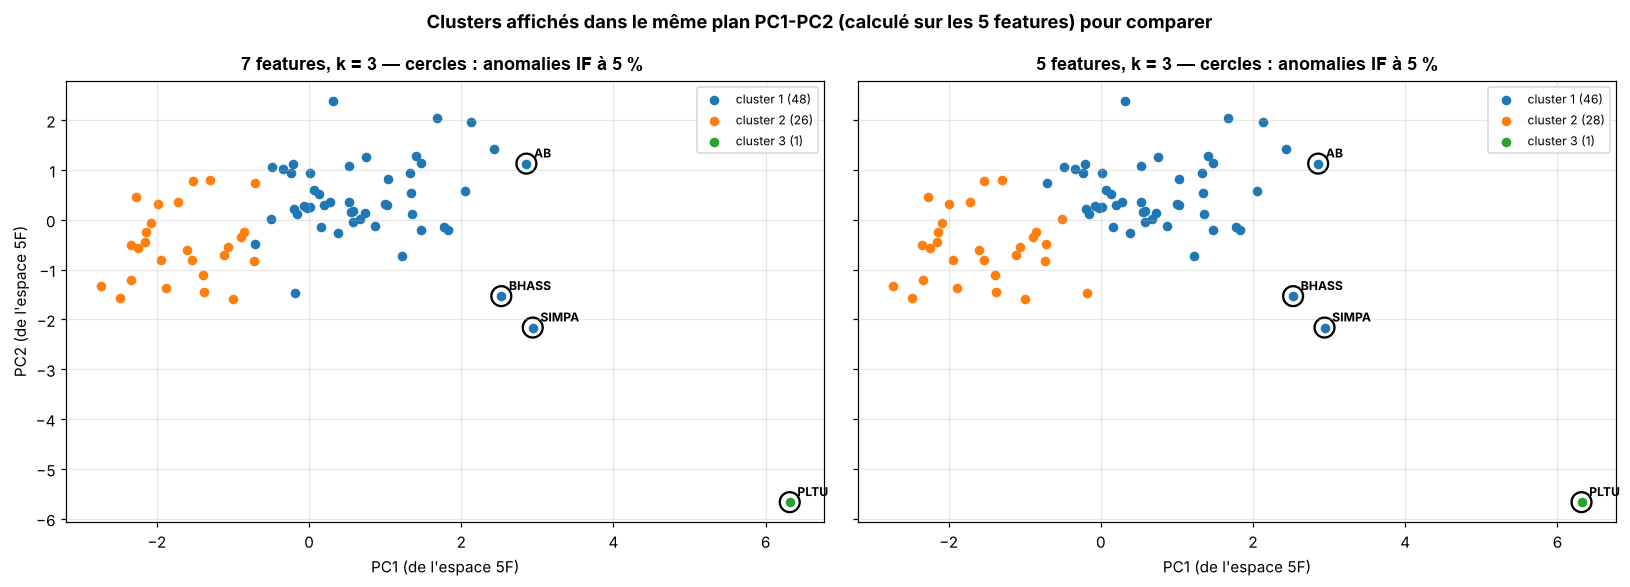

Le plan PC1-PC2 explique 76% de la variance des 5 features (affichage seulement).


In [50]:
pcs = PCA(n_components=2, random_state=GRAINE).fit(Z); P = pd.DataFrame(pcs.transform(Z), index=Z.index, columns=["PC1", "PC2"])
fig, ax = plt.subplots(1, 2, figsize=(15, 5.4), sharex=True, sharey=True)
for a, (lab, titre) in zip(ax, [(REFERENCE_7F["cluster_7F"], "7 features, k = 3"), (CL, f"5 features, k = {K}")]):
    for c in sorted(lab.unique()):
        m = lab == c; a.scatter(P.PC1[m], P.PC2[m], s=28, label=f"cluster {c} ({m.sum()})")
    an = a7 if "7 features" in titre else a5
    for t in an:
        a.scatter(P.PC1[t], P.PC2[t], s=170, facecolors="none", edgecolors="k", lw=1.5)
        a.annotate(t, (P.PC1[t], P.PC2[t]), xytext=(5, 4), textcoords="offset points", fontsize=8, fontweight="bold")
    a.set_title(titre + " — cercles : anomalies IF à 5 %"); a.set_xlabel("PC1 (de l'espace 5F)"); a.legend(fontsize=8)
ax[0].set_ylabel("PC2 (de l'espace 5F)")
fig.suptitle("Clusters affichés dans le même plan PC1-PC2 (calculé sur les 5 features) pour comparer", fontweight="bold")
fig.tight_layout(); fig.savefig(OUT / "s4b_clusters_7F_vs_5F.png", dpi=150); plt.show()
print(f"Le plan PC1-PC2 explique {pcs.explained_variance_ratio_.sum():.0%} de la variance des 5 features (affichage seulement).")

**Lecture de la comparaison.**
- **ARI = 0,80** : les deux partitions sont très proches. Seuls **4 titres sur 75** changent de groupe : AST, ICF et WIFAK passent du grand cluster au cluster « volatil, peu lié au marché », TINV fait le chemin inverse. Ce sont des titres proches de la frontière entre les deux groupes.
- **Anomalies à 5 % : identiques** (AB, BHASS, PLTU, SIMPA).
- **Conclusion** : les résultats de la phase de segmentation n'étaient pas un effet de la redondance des features. Avec 5 features, le modèle est plus simple, sans doublon, et donne les mêmes groupes et les mêmes anomalies.

### 8. Titres liquides seulement

Mêmes étapes sur les 57 titres échangés au moins 60 % des séances, avec une standardisation recalculée sur ces 57 titres.

5F, 57 liquides : votes {'coude': 5, 'silhouette': 3, 'calinski_harabasz': 3, 'davies_bouldin': 8} → k retenu = 3 (silhouette 0.286, tailles 24 / 18 / 15)
   contrôle hors plage : k=2 silhouette 0.361, k=9 silhouette 0.280, k=10 silhouette 0.284


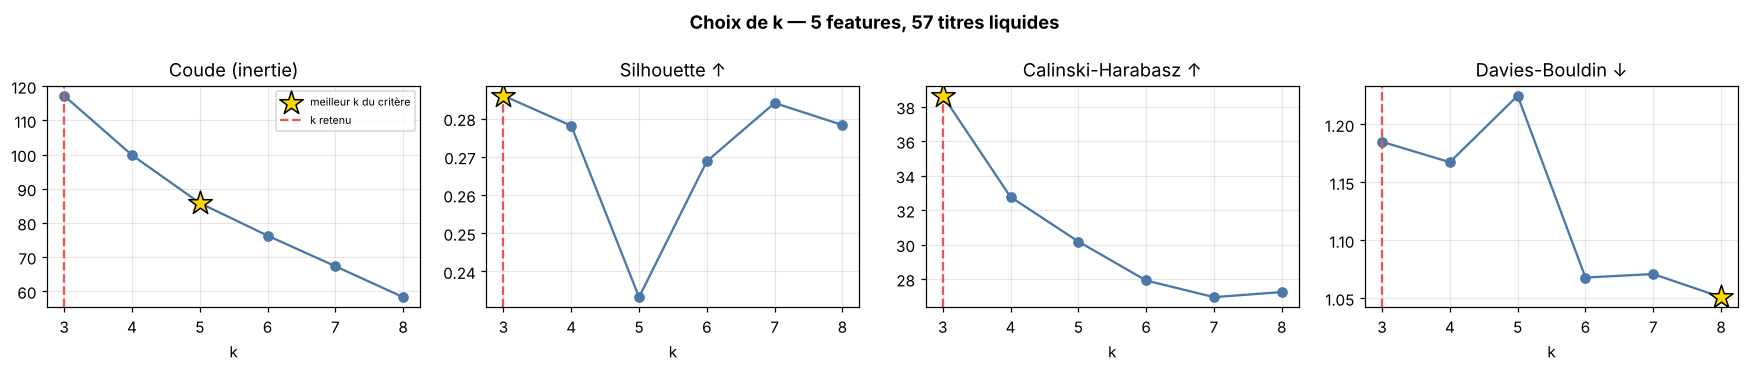

 cluster  taille  rendement_median  volatilite_mediane  skewness_mediane  cvar_mediane  beta_median  liquidite_mediane  nb_peu_liquides
       1      24             0.231               0.249             0.352        -0.035        0.541              0.930                0
       2      18             0.295               0.208             0.784        -0.026        0.774              0.993                0
       3      15            -0.033               0.382            -0.041        -0.045        0.144              0.838                0
cluster 1 (24) : AL, ARTES, ATB, BH, BNASS, CIL, CITY, ICF, LNDOR, MPBS, NAKL, SAM, SOTET, SPDIT, STA, STAR, STB, STPIL, TLNET, TLS, TRE, UIB, UMED, WIFAK
cluster 2 (18) : AB, AMV, ATL, BIAT, BNA, BT, CC, DH, MGR, OTH, PGH, SAH, SFBT, SMART, SOTUV, TJARI, TJL, TPR
cluster 3 (15) : ASSAD, BHL, BTE, CELL, ECYCL, MNP, NBL, PLAST, SCB, SIAME, SOKNA, SOMOC, STPAP, TAIR, TGH



taux  nb_signales                 titres_signales
  3%            2                        AB, CELL
  5%            3                 AB, SOTET, CELL
  8%            5       AB, SOTET, NBL, BHL, CELL
 10%            6 AB, SOTET, TAIR, NBL, BHL, CELL

ticker           nom  nb_signalements_sur_4  stable  part_seances_echangees                       nature                                                                   justification
    AB     AMEN BANK                      4    True                   0.993          performance extrême                           liquide (99%) ; extrêmes : skewness +3.0σ, CVaR +2.0σ
  CELL       CELLCOM                      4    True                   0.694 performance extrême (baisse)                                      liquide (69%) ; extrêmes : rendement −2.2σ
 SOTET       SOTETEL                      3    True                   0.988 performance extrême (hausse)                                      liquide (99%) ; extrêmes : rendement +2.2σ
   NBL N

In [51]:
F57 = F[info.liquide]; info57 = info[info.liquide]; Z57 = standardiser(F57)
TABK57, VOTES57, K57, HORS57 = choix_k(Z57, "5F, 57 liquides")
TABK57.to_csv(OUT / "choix_k_criteres_liquides.csv")
graph_k(TABK57, K57, "Choix de k — 5 features, 57 titres liquides", "s4b_choix_k_liquides.png")
CL57 = ajuster(Z57, K57).rename("cluster_5F_liquides")
INT57 = interpreter(CL57, F7, info); INT57.to_csv(OUT / "interpretation_clusters_liquides.csv", index=False)
print(INT57.drop(columns="titres").round(3).to_string(index=False))
for _, r in INT57.iterrows(): print(f"cluster {r.cluster} ({r.taille}) : {r.titres}")

SC57, SIG57 = isolation(Z57); NB57 = SIG57.sum(axis=1).rename("nb_signalements_sur_4")
STAB57 = pd.DataFrame([{"taux": f"{t:.0%}", "nb_signales": int(SIG57[t].sum()), "titres_signales": ", ".join(SIG57.index[SIG57[t]])} for t in TAUX_IF])
STAB57.to_csv(OUT / "stabilite_isolation_forest_liquides.csv", index=False); print(); print(STAB57.to_string(index=False))
ANO57 = table_anomalies(NB57, Z57, F7, info57, 4); ANO57.to_csv(OUT / "nature_anomalies_liquides.csv", index=False)
print(); print(ANO57.drop(columns=["rendement", "volatilite"]).to_string(index=False))
print("\nARI avec les clusters 7F liquides :", round(adjusted_rand_score(REFERENCE_7F.loc[CL57.index, "cluster_7F_liquides"], CL57), 3))

**Lecture (57 titres liquides).**
- Le vote retient encore **k = 3** (silhouette, CH), avec des groupes plus équilibrés (24 / 18 / 15) puisque PLTU et les titres figés sont retirés. Mais la silhouette est basse (**0,286**) et **k = 2 ferait mieux (0,361)** dans le contrôle hors plage : chez les titres liquides, k = 3 n'est pas un vrai optimum, la structure de groupes est très faible.
- Les trois groupes se lisent ainsi : un groupe « grandes capitalisations liées au marché » (cluster 2 : BIAT, SFBT, TJARI, AB… ; bêta 0,77), un groupe intermédiaire (cluster 1 ; bêta 0,54) et un groupe volatil, en baisse et peu lié au marché (cluster 3 ; rendement −3 %, volatilité 38 %).
- **Anomalies stables : AB, CELL et SOTET**, toutes liquides et expliquées par des features mesurables (AB : skewness +3,0σ ; CELL : rendement −2,2σ ; SOTET : rendement +2,2σ). Avec 7 features, la phase de segmentation trouvait AB, SOTET et WIFAK : AB et SOTET sont confirmés, WIFAK est remplacée par CELL.
- ARI avec les clusters 7F liquides de la phase de segmentation : 0,58, donc un accord moyen. Sans les titres illiquides, la partition est plus sensible au choix des features, ce qui confirme que les groupes y sont peu marqués.

### 9. Synthèse

In [52]:
res = info[["nom", "liquide", "part_seances_echangees"]].join(REFERENCE_7F[["cluster_7F"]]).join(CL).join(SC).join(NB)
res["signale_if_5F_5pct"] = SIG[TAUX_RETENU].astype(int)
res = res.join(CL57).join(SC57.rename("score_if_5F_liquides")).join(NB57.rename("nb_signalements_sur_4_liquides"))
res.to_csv(OUT / "resultats_par_titre.csv")

ctrl = {"5 features, aucune valeur manquante": F.shape == (75, 5) and F.notna().all().all(),
        "kurtosis et une mesure VaR/CVaR retirés": "kurtosis" in RETIREES and len(RETIREES) == 2,
        "k retenu dans la plage 3-8": K in K_PLAGE and K57 in K_PLAGE,
        "chaque titre a un cluster": CL.notna().all() and CL57.notna().all(),
        "taux 5 % = 4 titres signalés": int(SIG[TAUX_RETENU].sum()) == 4}
for c, ok in ctrl.items(): print(("OK   " if ok else "ÉCHEC"), c)
assert all(ctrl.values())
print("\nFichiers produits :")
for p in sorted(OUT.iterdir()): print("  ", p.name)

OK    5 features, aucune valeur manquante
OK    kurtosis et une mesure VaR/CVaR retirés
OK    k retenu dans la plage 3-8
OK    chaque titre a un cluster
OK    taux 5 % = 4 titres signalés

Fichiers produits :
   choix_features.csv
   choix_k_controle_hors_plage.csv
   choix_k_criteres.csv
   choix_k_criteres_liquides.csv
   comparaison_7F_vs_5F.csv
   correlations_features_pearson.csv
   correlations_features_spearman.csv
   interpretation_clusters.csv
   interpretation_clusters_liquides.csv
   nature_anomalies.csv
   nature_anomalies_liquides.csv
   resultats_par_titre.csv
   s4b_choix_k.png
   s4b_choix_k_liquides.png
   s4b_clusters_7F_vs_5F.png
   s4b_correlations_features.png
   s4b_scores_isolation_forest.png
   stabilite_isolation_forest.csv
   stabilite_isolation_forest_liquides.csv


#### Ce qu'il faut retenir

1. **Pourquoi 5 features** : skewness/kurtosis (0,92) et VaR/CVaR (0,89) comptaient deux fois la même information. On garde **rendement, volatilité, skewness, CVaR et bêta**.
2. **k = 3 est confirmé** sur les 75 titres (3 critères sur 4, et vrai optimum hors plage), avec les mêmes trois groupes qu'en phase de segmentation : liquide et lié au marché (46), volatil et peu lié au marché (28), PLTU seul.
3. **Les partitions 7F et 5F sont très proches** (ARI 0,80, 4 titres changent de groupe) et les **anomalies à 5 % sont identiques** : AB, BHASS, PLTU, SIMPA.
4. **La conclusion de la phase de segmentation tient** : la plupart des anomalies sont des artefacts d'illiquidité ; la redondance des features n'en était pas la cause.
5. **Limite** : la structure de groupes reste faible (silhouette 0,37 ; 0,29 sur les liquides, où k = 2 ferait mieux). Il reste aussi une corrélation forte volatilité/CVaR (−0,85), gardée volontairement car elles mesurent deux risques différents.

Aucune anomalie n'est présentée comme une société en difficulté : il faudrait une preuve externe (états financiers, communiqués du CMF ou de la BVMT).